# Análisis Multivariable

* Luisa Merlo García | A01067715
* Edgar Osvaldo Navarro | A01644488
* Ariana Guadalupe Rosales Villalobos | A01644773


# Ejercicio 1 (25 puntos)

In [1]:
import pandas as pd

# Cargar el archivo CSV en un DataFrame
df = pd.read_csv('crime_data.csv')

# Mostrar las dimensiones (filas, columnas)
print(df.shape)

(51, 8)


#### Graficas de Pares de variables

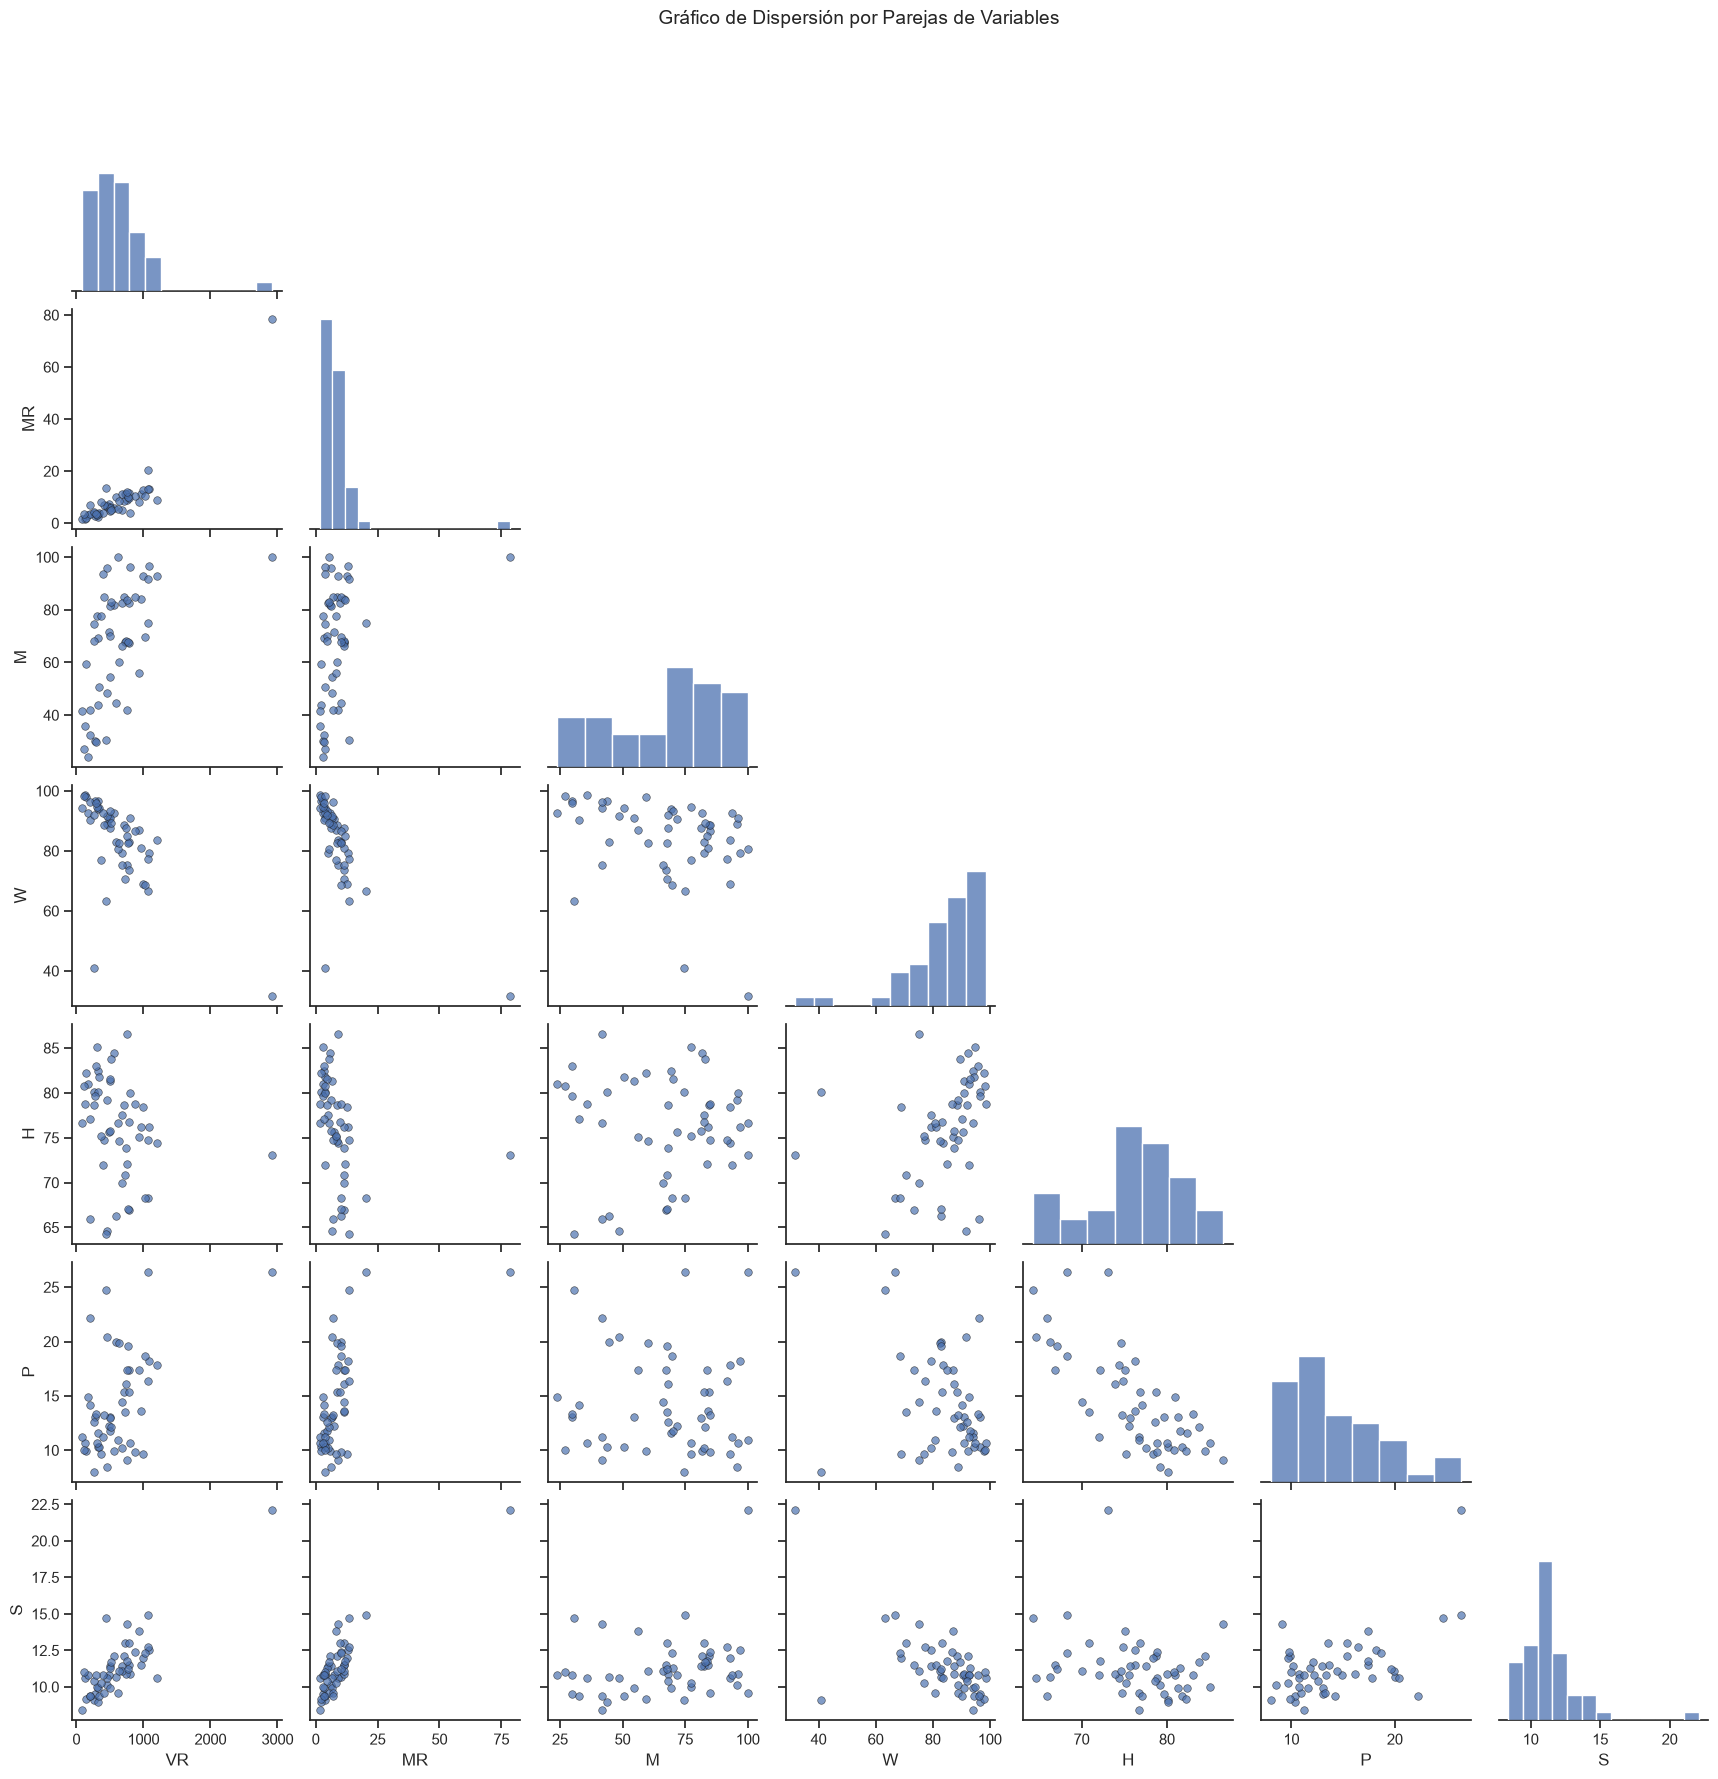

In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Cargar los datos
df = pd.read_csv('crime_data.csv')

# 2. Seleccionar las variables requeridas
variables = ['VR', 'MR', 'M', 'W', 'H', 'P', 'S']
df_subset = df[variables]

# 3. Crear la matriz de gráficos de dispersión (pairplot)
sns.set_theme(style="ticks")
g = sns.pairplot(
    df_subset, 
    corner=True,  # Evita repetir la mitad superior de la matriz por simetría
    plot_kws={'alpha': 0.7, 's': 30, 'edgecolor': 'k'}
)

g.fig.suptitle('Gráfico de Dispersión por Parejas de Variables', y=1.02, fontsize=14)

plt.show()

#### Valores medios de cada variable y la matriz de covarianza

In [3]:
medias = df_subset.mean()
print("--- VALORES MEDIOS ---")
print(medias)
print("\n" + "="*40 + "\n")

# 4. Calcular la matriz de covarianza
matriz_cov = df_subset.cov(ddof=1)  # ddof=1 para la muestra
print("--- MATRIZ DE COVARIANZA ---")
print(matriz_cov)

--- VALORES MEDIOS ---
VR    612.843137
MR      8.727451
M      67.390196
W      84.107843
H      76.223529
P      14.258824
S      11.325490
dtype: float64


--- MATRIZ DE COVARIANZA ---
               VR           MR            M            W           H  \
VR  194569.494902  4189.516392  5269.178431 -3959.434745 -631.596235   
MR    4189.516392   114.866431    74.390275  -100.315420  -17.145259   
M     5269.178431    74.390275   482.115702   -98.191322   -0.488365   
W    -3959.434745  -100.315420   -98.191322   175.636337   25.058412   
H     -631.596235   -17.145259    -0.488365    25.058412   31.271435   
P     1030.281412    27.802353    -6.093612   -23.641471  -19.071212   
S      785.012078    19.529286    12.102455   -18.463804   -2.607412   

              P           S  
VR  1030.281412  785.012078  
MR    27.802353   19.529286  
M     -6.093612   12.102455  
W    -23.641471  -18.463804  
H    -19.071212   -2.607412  
P     21.015271    5.335271  
S      5.335271    4.5007

#### Calcule la matriz de correlación y muestre el mapa de calor de las correlaciones y el mapa de calor de sus respectivos p-valores. 

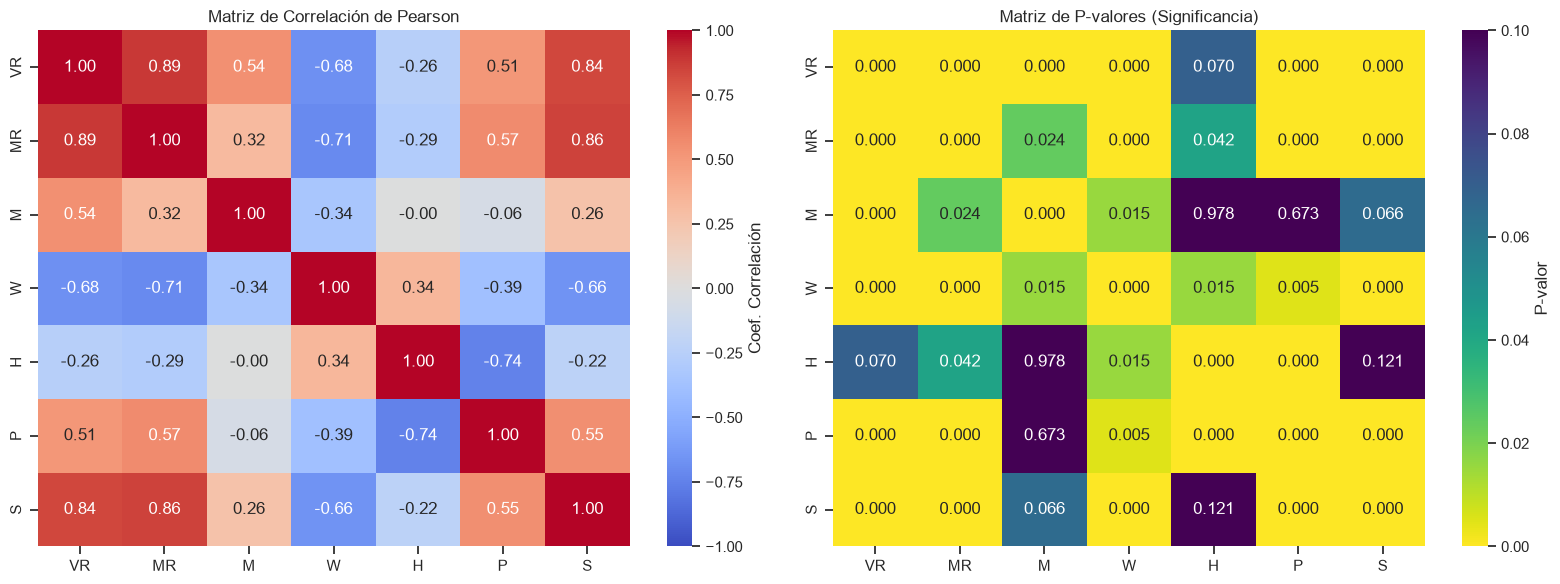

In [4]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import pearsonr


# 2. Calcular la matriz de correlación con pandas
corr_matrix = df_subset.corr(method='pearson')

# 3. Calcular la matriz de p-valores asegurando que sea de tipo float (float64)
n_vars = len(variables)
pval_matrix = pd.DataFrame(np.zeros((n_vars, n_vars), dtype=float), columns=variables, index=variables)

for col1 in variables:
    for col2 in variables:
        if col1 == col2:
            pval_matrix.loc[col1, col2] = 0.0  # p-valor de una variable consigo misma
        else:
            valid_data = df_subset[[col1, col2]].dropna()
            res = pearsonr(valid_data[col1], valid_data[col2])
            # Forzamos conversión a float nativo de Python para evitar problemas de tipos de NumPy
            pval_matrix.loc[col1, col2] = float(res.pvalue)

# 4. Graficar los Mapas de Calor
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Mapa de calor de Correlaciones
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1, ax=axes[0], cbar_kws={'label': 'Coef. Correlación'})
axes[0].set_title('Matriz de Correlación de Pearson')

# Mapa de calor de P-valores
sns.heatmap(pval_matrix, annot=True, fmt=".3f", cmap='viridis_r', vmin=0, vmax=0.1, ax=axes[1], cbar_kws={'label': 'P-valor'})
axes[1].set_title('Matriz de P-valores (Significancia)')

plt.tight_layout()
plt.show()

¿Qué correlaciones son significativas? 
Considerando un nivel de significandoa de a = 0.05, las correlaciones significativas serian las siguientes
| Variables | Correlación de Pearson (r) | P-valor | Interpretación |
|---|---:|---:|---|
| VR – MR | 0.89 | < 0.000 | Se relacionan de forma positiva. Como p < 0.05, existe suficiente evidencia para rechazar H₀, por lo cual las variables VR y MR tienen una relación lineal significativa.|
| VR – M | 0.54 | < 0.000 | Se relacionan de forma positiva. Como p < 0.05, existe suficiente evidencia para rechazar H₀, por lo cual las variables VR y M tienen una relación lineal significativa. |
| VR – W | -0.68 | < 0.000 | Se relacionan de forma negativa. Como p < 0.05, existe suficiente evidencia para rechazar H₀, por lo cual las variables VR y W tienen una relación lineal significativa: cuando una aumenta, la otra tiende a disminuir. |
| VR – P | 0.51 | < 0.000 | Se relacionan de forma positiva. Como p < 0.05, existe suficiente evidencia para rechazar H₀, por lo cual las variables VR y P tienen una relación lineal significativa. |
| VR – S | 0.84 | < 0.000 | Se relacionan de forma positiva. Como p < 0.05, existe suficiente evidencia para rechazar H₀, por lo cual las variables VR y S tienen una relación lineal significativa. |
| MR – M | 0.32 | 0.024 | Se relacionan de forma positiva. Como p < 0.05, existe suficiente evidencia para rechazar H₀, por lo cual las variables MR y M tienen una relación lineal significativa. |
| MR – W | -0.71 | < 0.000 | Se relacionan de forma negativa. Como p < 0.05, existe suficiente evidencia para rechazar H₀, por lo cual las variables MR y W tienen una relación lineal significativa: cuando una aumenta, la otra tiende a disminuir. |
| MR – H | -0.29 | 0.042 | Se relacionan de forma negativa débil. Como p < 0.05, existe suficiente evidencia para rechazar H₀, por lo cual las variables MR y H tienen una relación lineal significativa, aunque de baja intensidad. |
| MR – P | 0.57 | < 0.000 | Se relacionan de forma positiva. Como p < 0.05, existe suficiente evidencia para rechazar H₀, por lo cual las variables MR y P tienen una relación lineal significativa. |
| MR – S | 0.86 | < 0.000 | Se relacionan de forma positiva. Como p < 0.05, existe suficiente evidencia para rechazar H₀, por lo cual las variables MR y S tienen una relación lineal significativa. |
| M – W | -0.34 | 0.015 | Se relacionan de forma negativa. Como p < 0.05, existe suficiente evidencia para rechazar H₀, por lo cual las variables M y W tienen una relación lineal significativa: cuando una aumenta, la otra tiende a disminuir. |
| W – H | 0.34 | 0.015 | Se relacionan de forma positiva. Como p < 0.05, existe suficiente evidencia para rechazar H₀, por lo cual las variables W y H tienen una relación lineal significativa. |
| W – P | -0.39 | 0.005 | Se relacionan de forma negativa. Como p < 0.05, existe suficiente evidencia para rechazar H₀, por lo cual las variables W y P tienen una relación lineal significativa: cuando una aumenta, la otra tiende a disminuir. |
| W – S | -0.66 | < 0.000 | Se relacionan de forma negativa. Como p < 0.05, existe suficiente evidencia para rechazar H₀, por lo cual las variables W y S tienen una relación lineal significativa: cuando una aumenta, la otra tiende a disminuir. |
| H – P | -0.74 | < 0.000 | Se relacionan de forma negativa. Como p < 0.05, existe suficiente evidencia para rechazar H₀, por lo cual las variables H y P tienen una relación lineal significativa: cuando una aumenta, la otra tiende a disminuir. |
| P – S | 0.55 | < 0.000 | Se relacionan de forma positiva. Como p < 0.05, existe suficiente evidencia para rechazar H₀, por lo cual las variables P y S tienen una relación lineal significativa. |

#### Calcule la determinante de la matriz de covarianza.

In [5]:
# 2. Calcular la matriz de covarianza
matriz_cov = df_subset.cov()

# 3. Calcular el determinante de la matriz de covarianza
det_cov = np.linalg.det(matriz_cov)
print(f"Determinante de la matriz de covarianza: {det_cov}")

# Nota: A menudo es más útil evaluar la matriz de correlación para evitar el efecto de las unidades
corr_matrix = df_subset.corr()
det_corr = np.linalg.det(corr_matrix)
print(f"Determinante de la matriz de correlación: {det_corr}")

Determinante de la matriz de covarianza: 13257717261994.49
Determinante de la matriz de correlación: 0.0023684747723819706


Viendo este número, ¿consideras que hay multicolinealidad?

Si considero que existe multicolinealidad, porque el determinante de la matriz de correlación es cercano a cero, lo cual nos indica que las columnas están fuertemente relacionadas entre sí. En el caso del determinante de la matriz de covarianza, no nos da mucha información, ya que los datos están en distintas unidades; en cambio, el determinante de la matriz de correlación está acotado entre 0 y 1.

#### Muestre los histogramas de cada variable, los box-plots, y las gráficas de quantil-quantil para mostrar si tiene un comportamiento normal las variables.

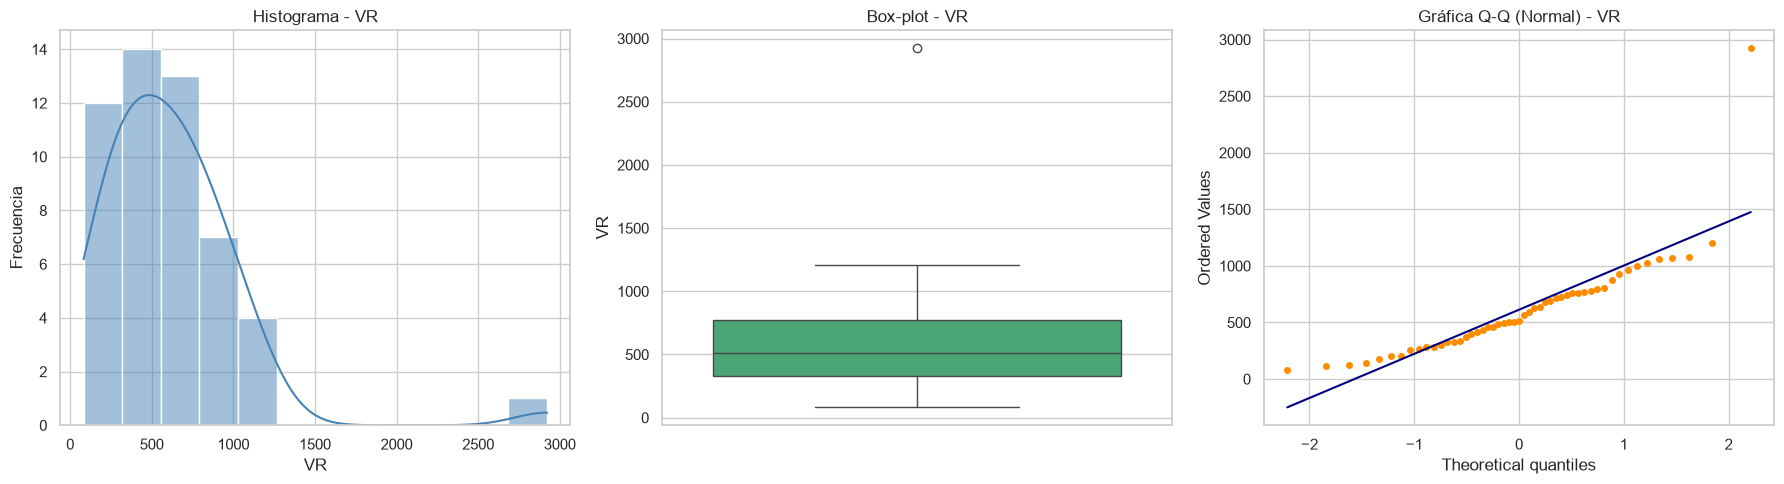

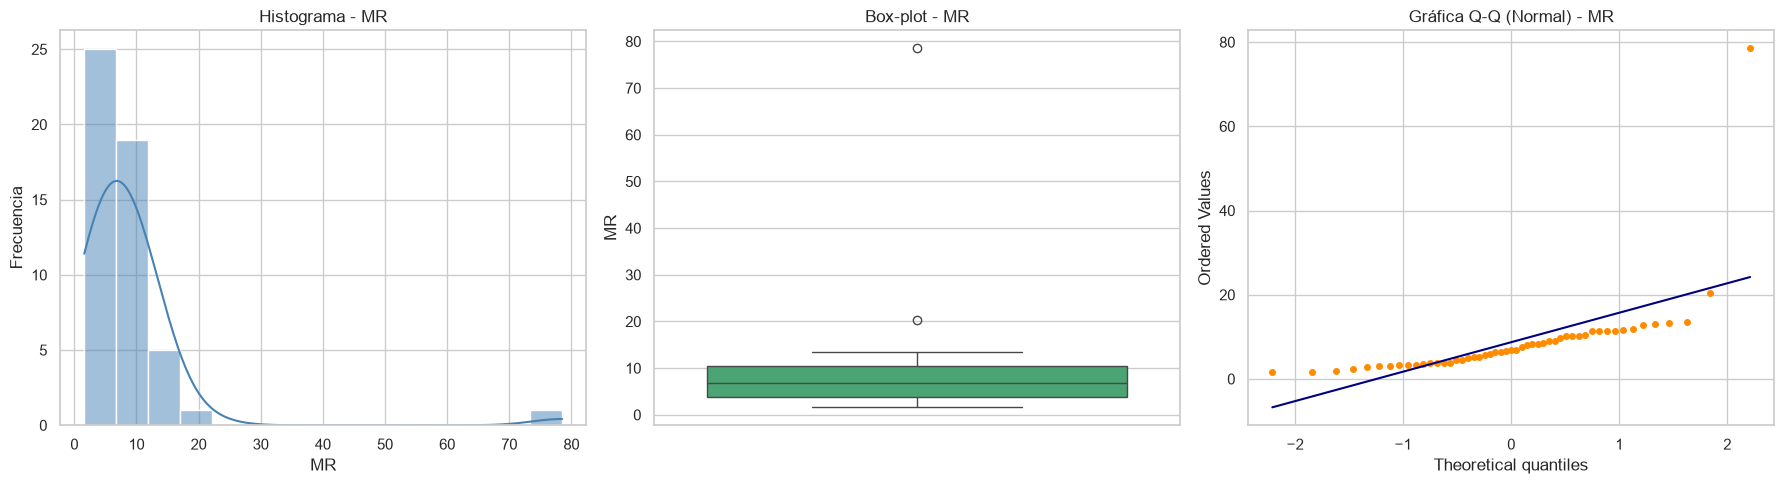

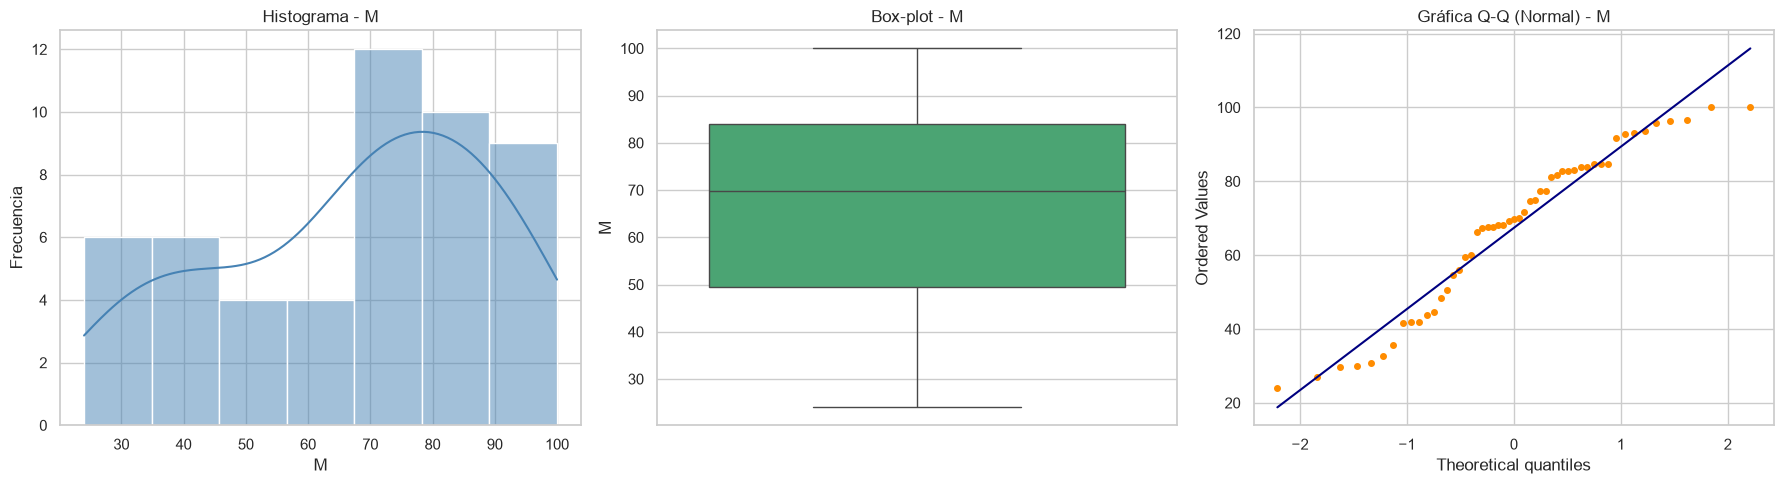

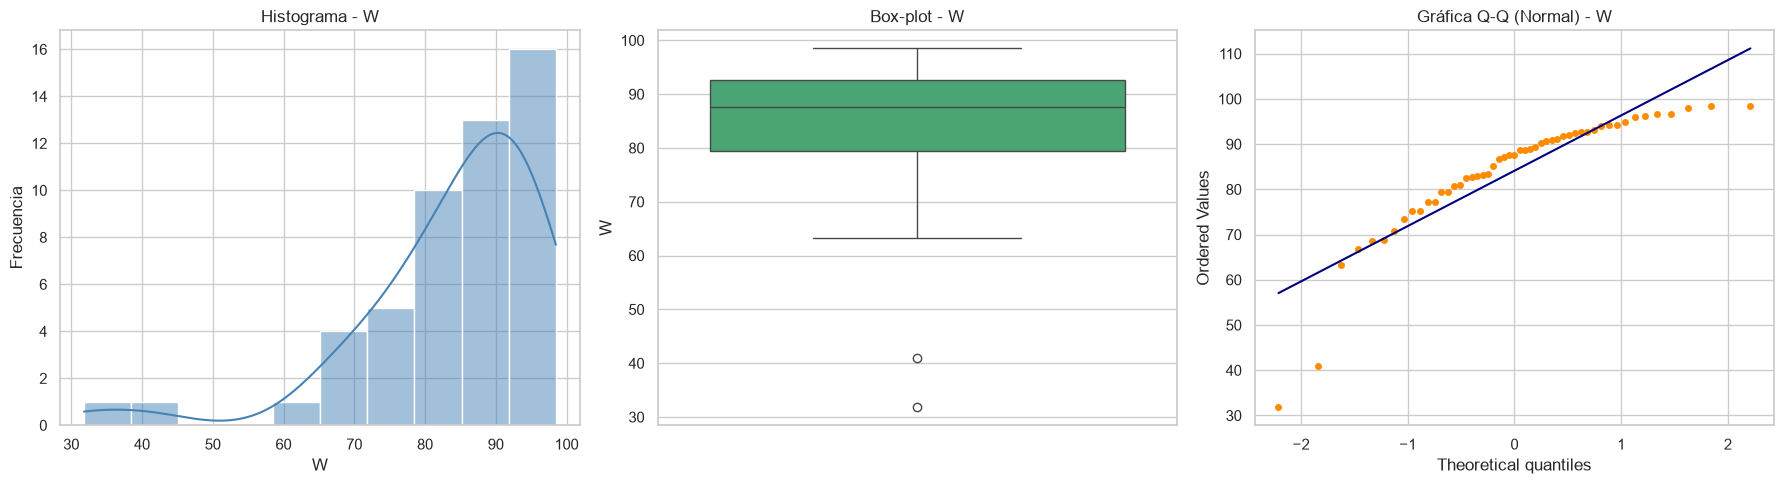

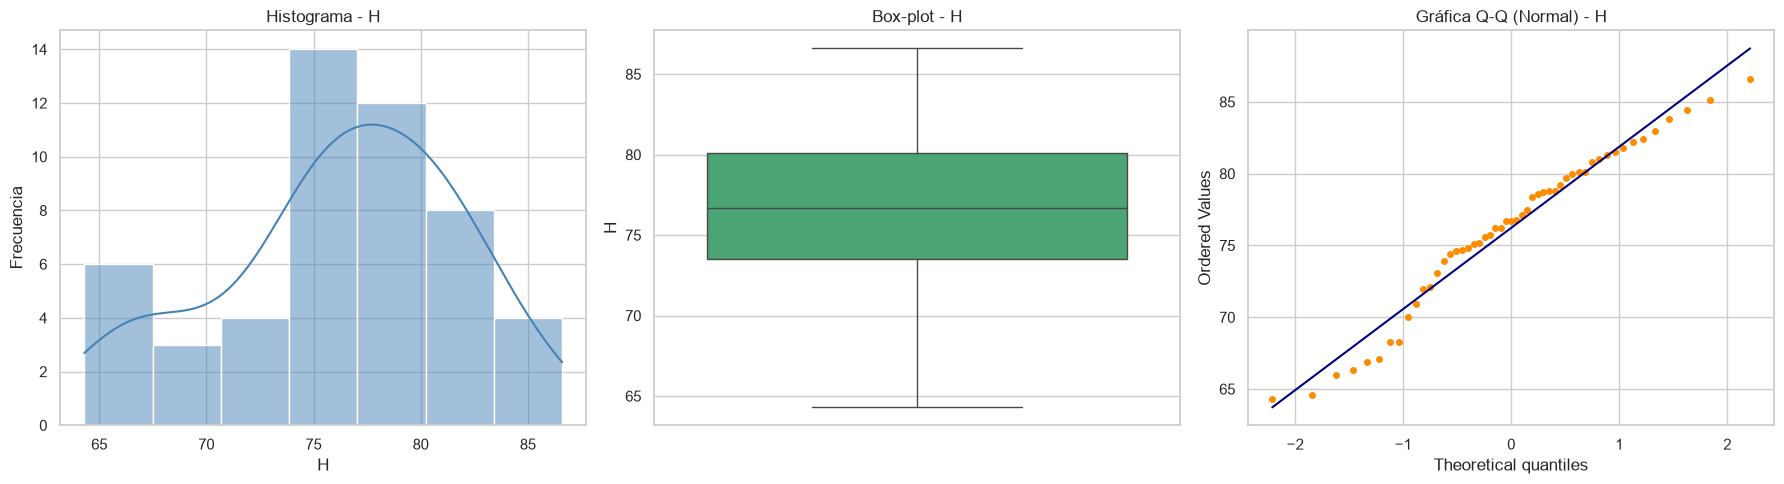

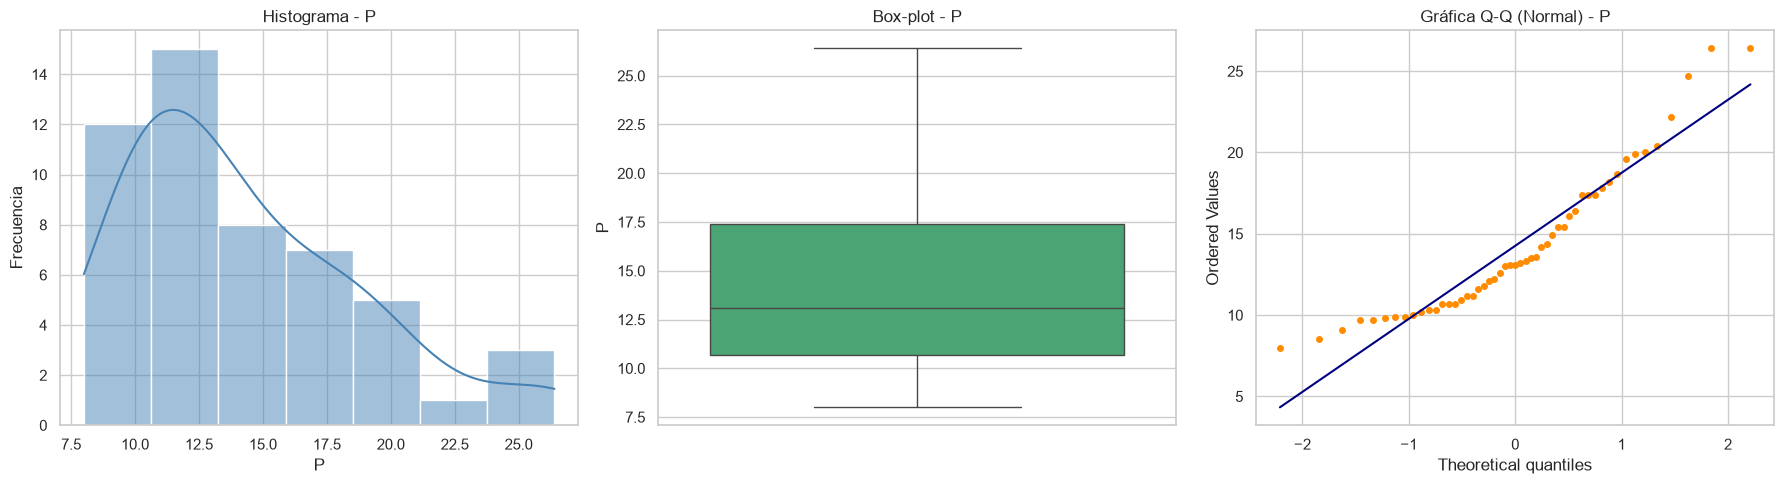

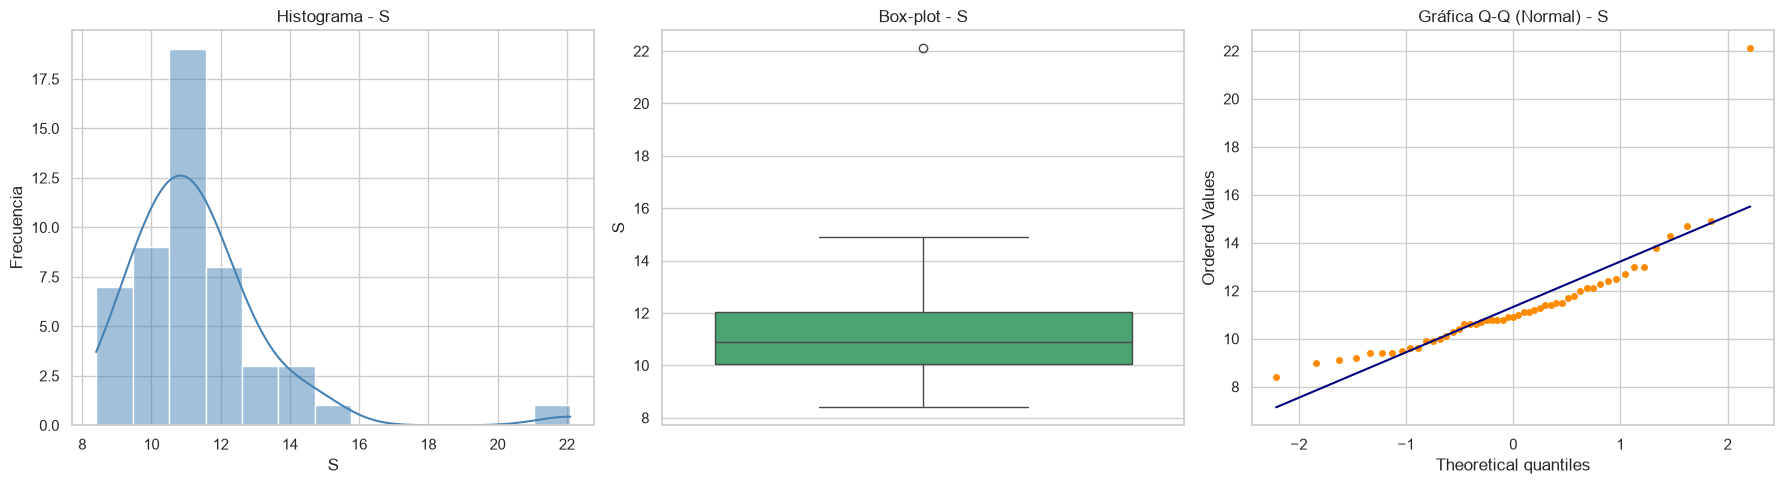

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
# 2. Configurar el estilo visual
sns.set_theme(style="whitegrid")

# 3. Iterar sobre cada variable para generar sus tres gráficos de normalidad
for var in variables:
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    
    # A. Histograma con KDE (Curva de densidad)
    sns.histplot(df[var].dropna(), kde=True, ax=axes[0], color='steelblue')
    axes[0].set_title(f'Histograma - {var}')
    axes[0].set_xlabel(var)
    axes[0].set_ylabel('Frecuencia')
    
    # B. Box-plot (Diagrama de caja)
    sns.boxplot(y=df[var].dropna(), ax=axes[1], color='mediumseagreen')
    axes[1].set_title(f'Box-plot - {var}')
    axes[1].set_ylabel(var)
    
    # C. Gráfica Q-Q (Cuantil-Cuantil Normal)
    stats.probplot(df[var].dropna(), dist="norm", plot=axes[2])
    axes[2].set_title(f'Gráfica Q-Q (Normal) - {var}')
    axes[2].get_lines()[0].set_marker('o')
    axes[2].get_lines()[0].set_markersize(4)
    axes[2].get_lines()[0].set_color('darkorange')
    axes[2].get_lines()[1].set_color('navy') # Línea teórica
    
    plt.tight_layout()
    plt.show()

VR: A través del histograma podemos observar que los datos se encuentran sesgados hacia la derecha. En el box-plot se identifica un valor atípico con un valor aproximado de 2900. En el Q-Q plot se encontró que los puntos se devsian respecto a la recta, especialmente en las colas, lo cual representa un comportamiento no normal.

MR: A través del histograma podemos observar que los datos se encuentran sesgados hacia la derecha, con la mayoría de los valores concentrados entre 0 y 20. En el box-plot se identifican dos valores atípicos, uno con un valor aproximado de 20 y otro de 78. En el Q-Q plot se encontró que los puntos se desvían respecto a la recta, especialmente en las colas, y el valor más alto se aleja mucho de ella, lo cual representa un comportamiento no normal.

M: A través del histograma podemos observar que los datos se encuentran sesgados hacia la izquierda, con la mayoría de los valores concentrados entre 65 y 100 y una distribución que no tiene forma de campana. En el Q-Q plot se encontró que los puntos se desvían ligeramente de la recta, especialmente en las colas, aunque en general la siguen de forma aproximada, por lo que se considera que M se aproxima a un comportamiento normal, aunque con cierta asimetría.

W: A través del histograma podemos observar que los datos se encuentran sesgados hacia la izquierda, con la mayoría de los valores concentrados entre 80 y 100. En el box-plot se identifican dos valores atípicos, con valores aproximados de 32 y 41. En el Q-Q plot se encontró que los puntos se desvían respecto a la recta, especialmente en las colas (los dos valores más bajos se alejan mucho de ella), lo cual representa un comportamiento no normal.

H: A través del histograma podemos observar que los datos tienen una forma aproximadamente de campana, con una ligera asimetría hacia la izquierda y la mayoría de los valores concentrados entre 74 y 84. En el Q-Q plot se encontró que los puntos siguen de cerca la recta, con pequeñas desviaciones en las colas, lo cual representa un comportamiento aproximadamente normal.

P: A través del histograma podemos observar que los datos se encuentran sesgados hacia la derecha, con la mayoría de los valores concentrados entre 8 y 15. En el Q-Q plot se encontró que los puntos se desvían respecto a la recta, especialmente en las colas (la superior se eleva por encima de la recta), lo cual representa un comportamiento no normal, aunque con un sesgo moderado.

S: A través del histograma podemos observar que los datos se encuentran sesgados hacia la derecha, con la mayoría de los valores concentrados entre 9 y 13. En el box-plot se identifica un valor atípico con un valor aproximado de 22. En el Q-Q plot se encontró que los puntos se desvían respecto a la recta, especialmente en las colas, y el valor más alto se aleja mucho de ella, lo cual representa un comportamiento no normal.

En general, las variables VR, MR, W, P y S no presentan un comportamiento normal, ya que muestran sesgo y valores atípicos. En cambio, M y H se aproximan más a un comportamiento normal, aunque M tiene cierta asimetría.

#### Detecte valores atípicos utilizando el método de la distancia de Mahalanobis.

In [7]:
import pandas as pd
import numpy as np
from scipy.stats import chi2


# 2. Calcular la media y la matriz de covarianza invertida
mean_vector = df_subset.mean()
cov_matrix = df_subset.cov(ddof=1)  # ddof=1 para la muestra
inv_cov_matrix = np.linalg.inv(cov_matrix)

# 3. Calcular la distancia de Mahalanobis para cada observación
def mahalanobis(row):
    diff = row - mean_vector
    # D^2 = (x - mu)^T * S^(-1) * (x - mu)
    d_sq = np.dot(np.dot(diff, inv_cov_matrix), diff)
    return np.sqrt(d_sq)

df['Mahalanobis_Dist'] = df_subset.apply(mahalanobis, axis=1)

# 4. Calcular el p-valor basado en la distribución Chi-cuadrada (grados de libertad = número de variables)
df['Mahalanobis_P_Value'] = 1 - chi2.cdf(df['Mahalanobis_Dist']**2, df=len(variables))

# 5. Filtrar valores atípicos usando un umbral de significancia
outliers = df[df['Mahalanobis_P_Value'] < 0.01]

print("--- OBSERVACIONES IDENTIFICADAS COMO ATÍPICAS con un aplha de 0.01 ---")
print(outliers[['VR', 'MR', 'M', 'W', 'H', 'P', 'S', 'Mahalanobis_Dist', 'Mahalanobis_P_Value']])


# 5. Filtrar valores atípicos usando un umbral de significancia
outliers = df[df['Mahalanobis_P_Value'] < 0.001]

print("--- OBSERVACIONES IDENTIFICADAS COMO ATÍPICAS con un aplha de 0.001 ---")
print(outliers[['VR', 'MR', 'M', 'W', 'H', 'P', 'S', 'Mahalanobis_Dist', 'Mahalanobis_P_Value']])

--- OBSERVACIONES IDENTIFICADAS COMO ATÍPICAS con un aplha de 0.01 ---
      VR    MR      M     W     H     P     S  Mahalanobis_Dist  \
10   261   3.8   74.7  40.9  80.1   8.0   9.1          5.900939   
24   434  13.5   30.7  63.3  64.3  24.7  14.7          4.558563   
50  2922  78.5  100.0  31.8  73.1  26.4  22.1          6.816612   

    Mahalanobis_P_Value  
10         1.208444e-05  
24         4.108979e-03  
50         7.093202e-08  
--- OBSERVACIONES IDENTIFICADAS COMO ATÍPICAS con un aplha de 0.001 ---
      VR    MR      M     W     H     P     S  Mahalanobis_Dist  \
10   261   3.8   74.7  40.9  80.1   8.0   9.1          5.900939   
50  2922  78.5  100.0  31.8  73.1  26.4  22.1          6.816612   

    Mahalanobis_P_Value  
10         1.208444e-05  
50         7.093202e-08  


 ¿Qué acciones tomarías para los valores atípicos encontrados?

Eliminaría las observaciones 10 y 50, ya que con un nivel de significancia de α = 0.001 son identificadas como atípicas, lo cual podría distorsionar el análisis y la matriz de covarianza. La observación 24 es atípica con α = 0.01 pero no con α = 0.001, por lo se podria conservar al tratarse de un registro plausible, verificando que los resultados no cambian de forma importante al incluirla o excluirla.

#### Aplique análisis de componentes principales sobre tu conjunto de datos, e indique con cuantos componentes se puede representar los datos para una variabilidad por encima del 90%. 

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

X = df[variables]

# 2. Paso CRUCIAL: Estandarizar las variables (media 0, varianza 1)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 3. Aplicar PCA
pca = PCA()
X_pca = pca.fit_transform(X_scaled)

# 4. Calcular varianza explicada e individual y acumulada
varianza_explicada = pca.explained_variance_ratio_
varianza_acumulada = np.cumsum(varianza_explicada)

# 5. Determinar número de componentes para > 90%
n_componentes_90 = np.argmax(varianza_acumulada >= 0.90) + 1

# Imprimir resultados
print("--- RESULTADOS PCA ---")
for i, (var_ind, var_acum) in enumerate(zip(varianza_explicada, varianza_acumulada), 1):
    print(f"Componente {i}: {var_ind*100:.2f}% de varianza (Acumulada: {var_acum*100:.2f}%)")

print(f"\nNúmero de componentes necesarios para > 90% de varianza: {n_componentes_90}")

--- RESULTADOS PCA ---
Componente 1: 57.75% de varianza (Acumulada: 57.75%)
Componente 2: 20.45% de varianza (Acumulada: 78.19%)
Componente 3: 10.68% de varianza (Acumulada: 88.88%)
Componente 4: 6.33% de varianza (Acumulada: 95.21%)
Componente 5: 2.00% de varianza (Acumulada: 97.20%)
Componente 6: 1.79% de varianza (Acumulada: 98.99%)
Componente 7: 1.01% de varianza (Acumulada: 100.00%)

Número de componentes necesarios para > 90% de varianza: 4


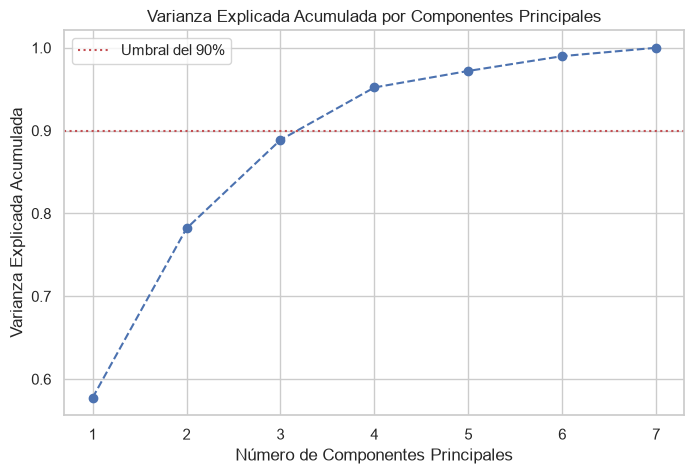

In [9]:
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(varianza_acumulada) + 1), varianza_acumulada, marker='o', linestyle='--', color='b')
plt.axhline(y=0.90, color='r', linestyle=':', label='Umbral del 90%')
plt.title('Varianza Explicada Acumulada por Componentes Principales')
plt.xlabel('Número de Componentes Principales')
plt.ylabel('Varianza Explicada Acumulada')
plt.grid(True)
plt.legend()
plt.show()

A través del PCA se puede concluir que el primer componente explica el 57.75 % de la varianza y el segundo el 20.45 %, acumulando un 78.19 % con dos componentes. Usando un umbral del 90 % de varianza explicada se requerirían 4 componentes (95.21 %), por lo tanto, es posible reducir la dimensionalidad del problema de 7 variables a 4 componentes principales sin perder una gran cantidad de información.

#### Considera a VR y MR como un grupo de variables, y al resto como otro grupo de variables, y realiza el análisis de correlación canónica sobre los grupos de variables. 


In [10]:

from statsmodels.multivariate.cancorr import CanCorr

y1 = df[['VR', 'MR']]                    # Grupo 1: Variables de criminalidad
y2 = df[['M', 'W', 'H', 'P', 'S']]       # Grupo 2: Variables socioeconómicas y demográficas

# 3. Ajustar el modelo de Correlación Canónica
cca_model = CanCorr(y1, y2)

print("--- CORRELACIONES CANÓNICAS ---")
print(cca_model.cancorr)

# 5. Obtener los coeficientes canónicos (pesos) para ambos grupos
print("\nCoeficientes canónicos para el Grupo 1 (y1):")
print(cca_model.y_cancoef)

print("\nCoeficientes canónicos para el Grupo 2 (y2):")
print(cca_model.x_cancoef)

# 6. Pruebas de significancia para las dimensiones canónicas
print("\nPruebas estadísticas de correlación:")
print(cca_model.corr_test())

--- CORRELACIONES CANÓNICAS ---
[0.92788804 0.52900443]

Coeficientes canónicos para el Grupo 1 (y1):
[[-0.00023262  0.00065173]
 [-0.00394309 -0.02820617]]

Coeficientes canónicos para el Grupo 2 (y2):
[[-2.12443576e-03  6.65220308e-03]
 [ 1.95628200e-03  4.92165350e-03]
 [-3.01580406e-03  1.03819518e-05]
 [-9.05003770e-03  1.33261769e-03]
 [-3.94465752e-02 -1.57479108e-02]]

Pruebas estadísticas de correlación:
                          Cancorr results
  Canonical Correlation Wilks' lambda  Num DF  Den DF F Value Pr > F
--------------------------------------------------------------------
0                0.9279        0.1001 10.0000 94.0000 20.3078 0.0000
1                0.5290        0.7202  4.0000 48.0000  4.6631 0.0029
--------------------------------------------------------------------
                                                                    
--------------------------------------------------------------------
Multivariate Statistics and F Approximations              

In [11]:
cca_model.corr_test().summary()

<class 'statsmodels.iolib.summary2.Summary'>
"""
                          Cancorr results
====================================================================
  Canonical Correlation Wilks' lambda  Num DF  Den DF F Value Pr > F
--------------------------------------------------------------------
0                0.9279        0.1001 10.0000 94.0000 20.3078 0.0000
1                0.5290        0.7202  4.0000 48.0000  4.6631 0.0029
--------------------------------------------------------------------
                                                                    
--------------------------------------------------------------------
Multivariate Statistics and F Approximations                        
----------------------------------------------------------------------
                         Value     Num DF    Den DF   F Value   Pr > F
----------------------------------------------------------------------
Wilks' lambda            0.1001   10.0000   88.0000   19.0116   0.0000
Pillai's trace           1.1408   10.0000   90.0000   11.9503   0.0000
Hotelling-Lawley trace   6.5816   10.0000   63.3103   28.5445   0.0000
Roy's greatest root      6.1930    5.0000   45.0000   55.7371   0.0000
====================================================================

"""

A través de este análisis de correlación canónica se observa que el grupo 1 (criminalidad) y el grupo 2 (contexto social) están fuertemente relacionados y de forma significativa, con una primera correlación canónica de r = 0.93 y p < 0.001. Una segunda dimensión, más débil (r = 0.53, p = 0.003), también resultó significativa. Esto indica asociación entre ambos grupos, no causalidad.

#### Escriba una conclusión sobre los hallazgos más importantes de este ejercicio. ¿Qué recomendarías a un funcionario público viendo estos datos?

En el ejercicio se encontró que las variables VR y MR están altamente correlacionadas, por lo tanto los crímenes violentos están altamente relacionados con los asesinatos. A su vez, los factores que más se relacionaban con estas variables serían S de forma positiva y W de forma negativa, por lo tanto el porcentaje de familias con un solo miembro adulto como tutor está relacionado de forma lineal y positivamente con los crímenes y asesinatos, a su vez que el porcentaje de gente blanca está relacionado de forma lineal y negativamente con los crímenes y asesinatos. También se concluyó que las variables tenían multicolinealidad al tener un determinante de la matriz de correlación cercano a cero, y mediante PCA se obtuvo que con 4 componentes se podría representar más del 90% de la varianza. Al final mediante la correlación canónica se obtuvo que el grupo de criminalidad y el grupo de contexto social estaban ligados fuertemente y de forma significativa (r = 0.93, p < 0.001).

A un funcionario público le recomendaría enfocarse principalmente en las zonas de mayor riesgo, que serían las zonas donde haya más familias con un solo tutor legal. A su vez, sería importante enfocarse en zonas donde todas estas variables se presenten al mismo tiempo, ya que están muy relacionadas entre sí y conviene atender el problema de forma integral considerando multiples variables a la vez.

# Ejercicio 2

In [12]:
import pandas as pd
import numpy as np

df = pd.read_csv('WHR_2015.csv')
print(df.shape)
print(df.isna().sum())

# Abreviaturas para que las gráficas se lean bien
nombres = {
    'happiness_score': 'HS',
    'gdp_per_capita': 'GDP',
    'social_support': 'SS',
    'healthy_life_expectancy': 'LE',
    'freedom_to_make_life_choices': 'FR',
    'generosity': 'GEN',
    'perceptions_of_corruption': 'COR'
}
df = df.rename(columns=nombres)

variables = list(nombres.values())
df = df.dropna(subset=variables).reset_index(drop=True)
df_subset = df[variables]
print(df.shape)

(158, 9)
country                         0
region                          0
happiness_score                 0
gdp_per_capita                  0
social_support                  0
healthy_life_expectancy         0
freedom_to_make_life_choices    0
generosity                      0
perceptions_of_corruption       0
dtype: int64
(158, 9)


#### Grafique cada pareja de variables.

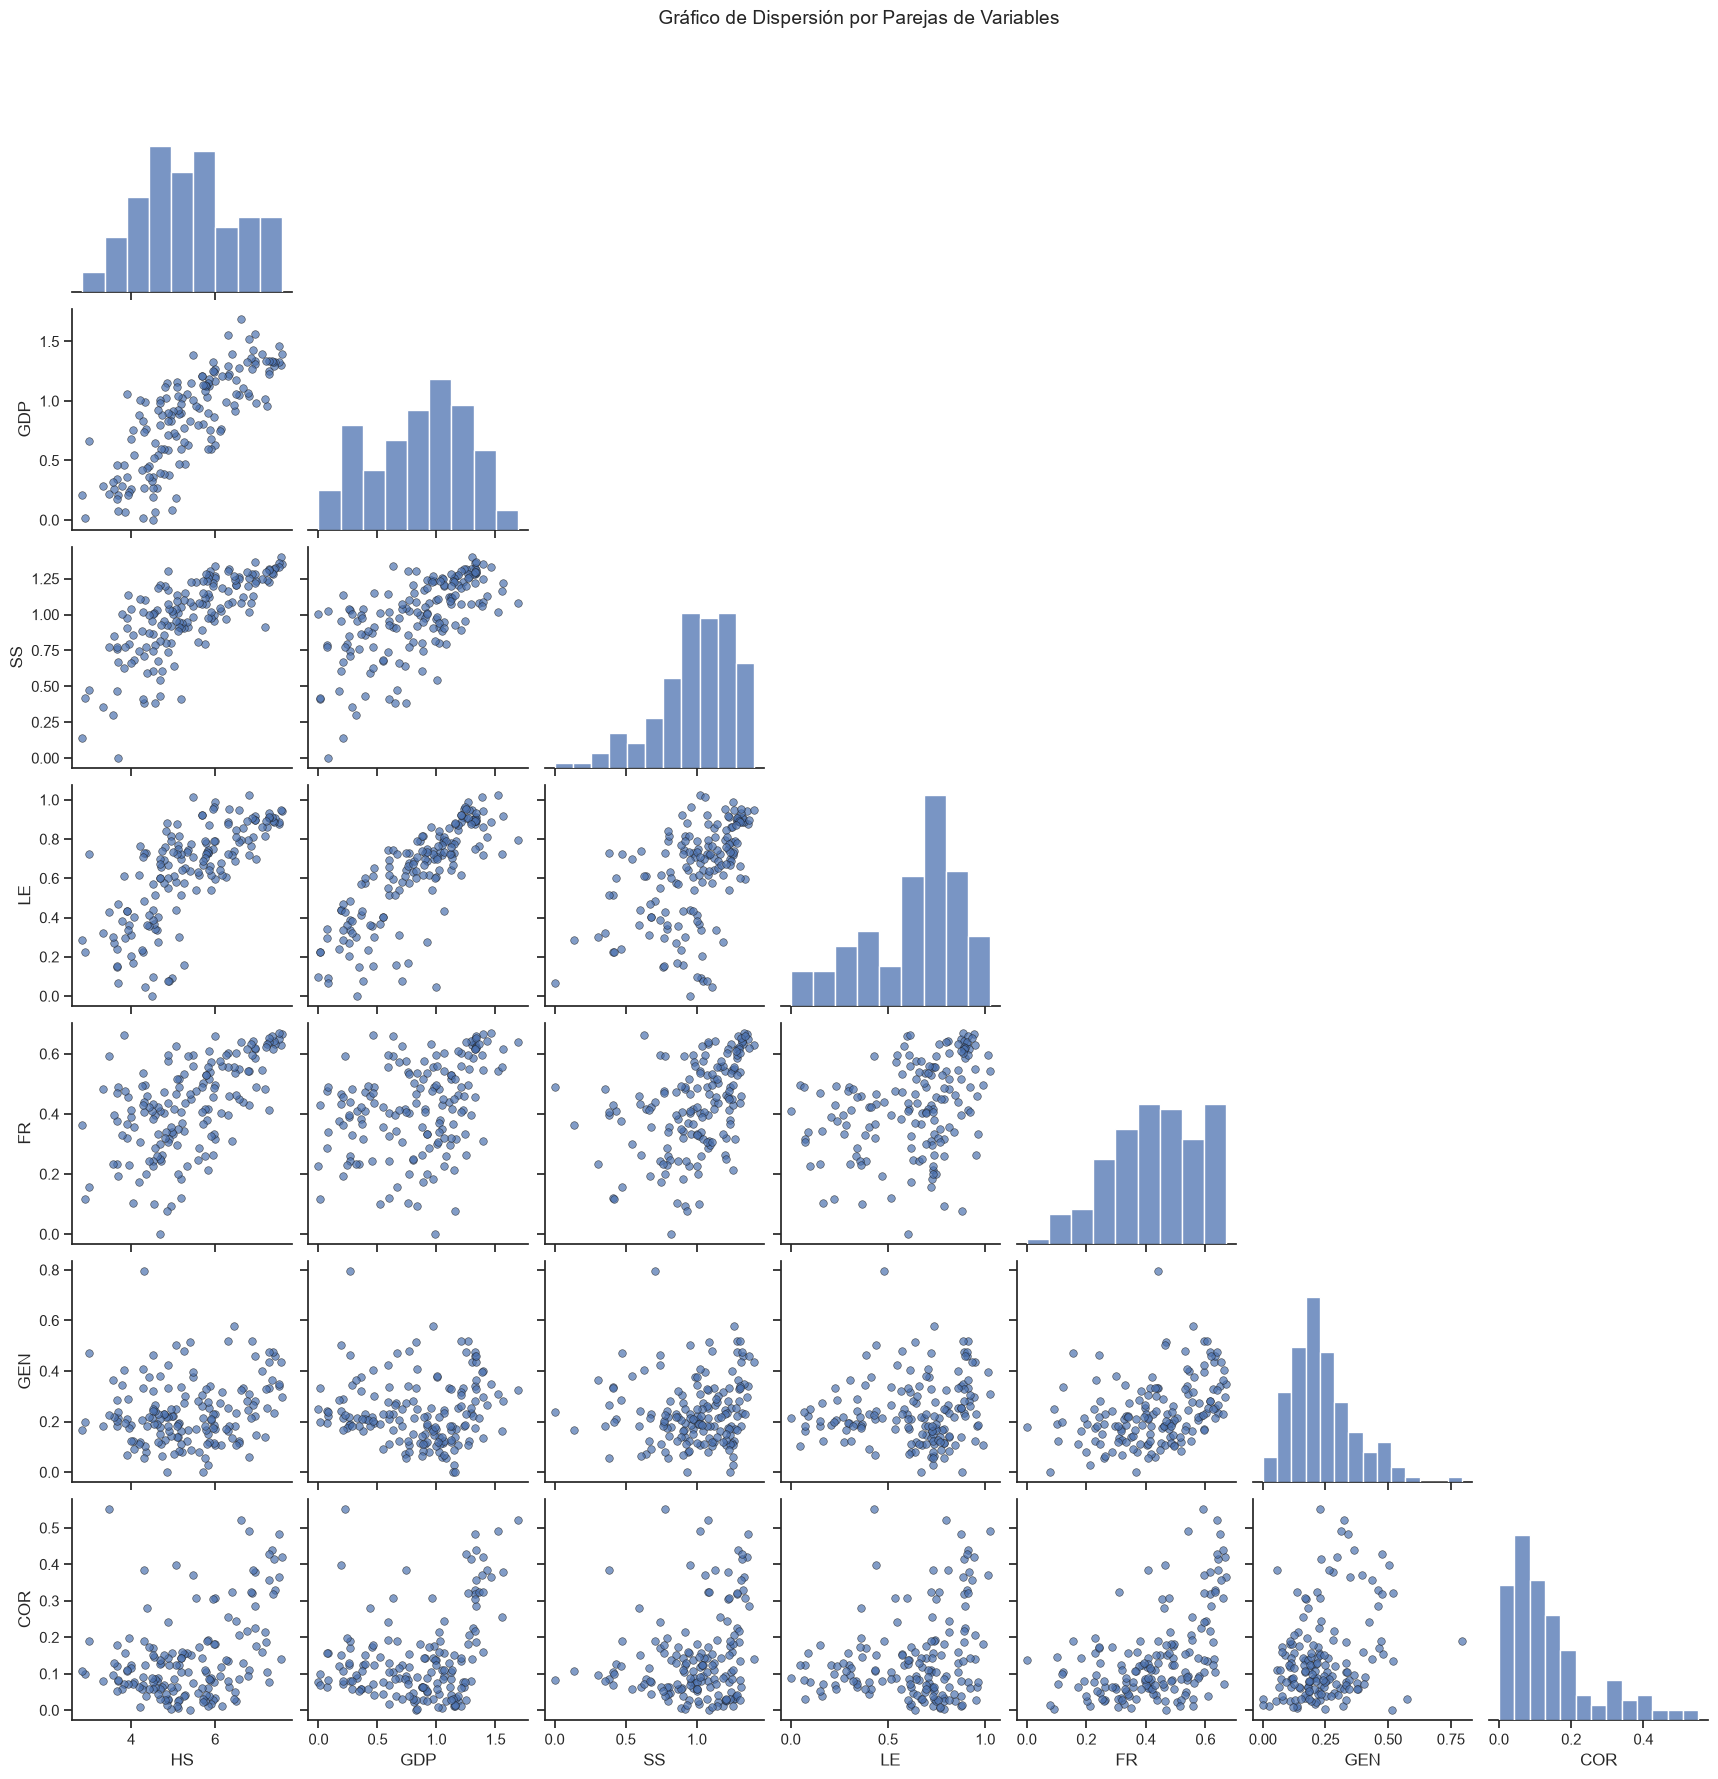

In [13]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="ticks")
g = sns.pairplot(df_subset, corner=True,
                 plot_kws={'alpha': 0.7, 's': 30, 'edgecolor': 'k'})
g.fig.suptitle('Gráfico de Dispersión por Parejas de Variables', y=1.02, fontsize=14)
plt.show()

#### Indique los valores medios de cada variable y la matriz de covarianza .

In [14]:
medias = df_subset.mean()
print("--- VALORES MEDIOS ---")
print(medias)
print("\n" + "="*40 + "\n")

matriz_cov = df_subset.cov(ddof=1)
print("--- MATRIZ DE COVARIANZA ---")
print(matriz_cov)

--- VALORES MEDIOS ---
HS     5.375734
GDP    0.846137
SS     0.991046
LE     0.630259
FR     0.428615
GEN    0.237296
COR    0.143422
dtype: float64


--- MATRIZ DE COVARIANZA ---
           HS       GDP        SS        LE        FR       GEN       COR
HS   1.311048  0.360476  0.230969  0.204881  0.098042  0.026156  0.054316
GDP  0.360476  0.162506  0.070852  0.081323  0.022495 -0.000534  0.014898
SS   0.230969  0.070852  0.074185  0.035741  0.018122  0.003020  0.006722
LE   0.204881  0.081323  0.035741  0.061047  0.013422  0.003391  0.007365
FR   0.098042  0.022495  0.018122  0.013422  0.022708  0.007138  0.008927
GEN  0.026156 -0.000534  0.003020  0.003391  0.007138  0.016049  0.004199
COR  0.054316  0.014898  0.006722  0.007365  0.008927  0.004199  0.014408


#### Calcule la matriz de correlación y muestre el mapa de calor de las correlaciones y el mapa de calor de sus respectivos p-valores. ¿Qué correlaciones son significativas?

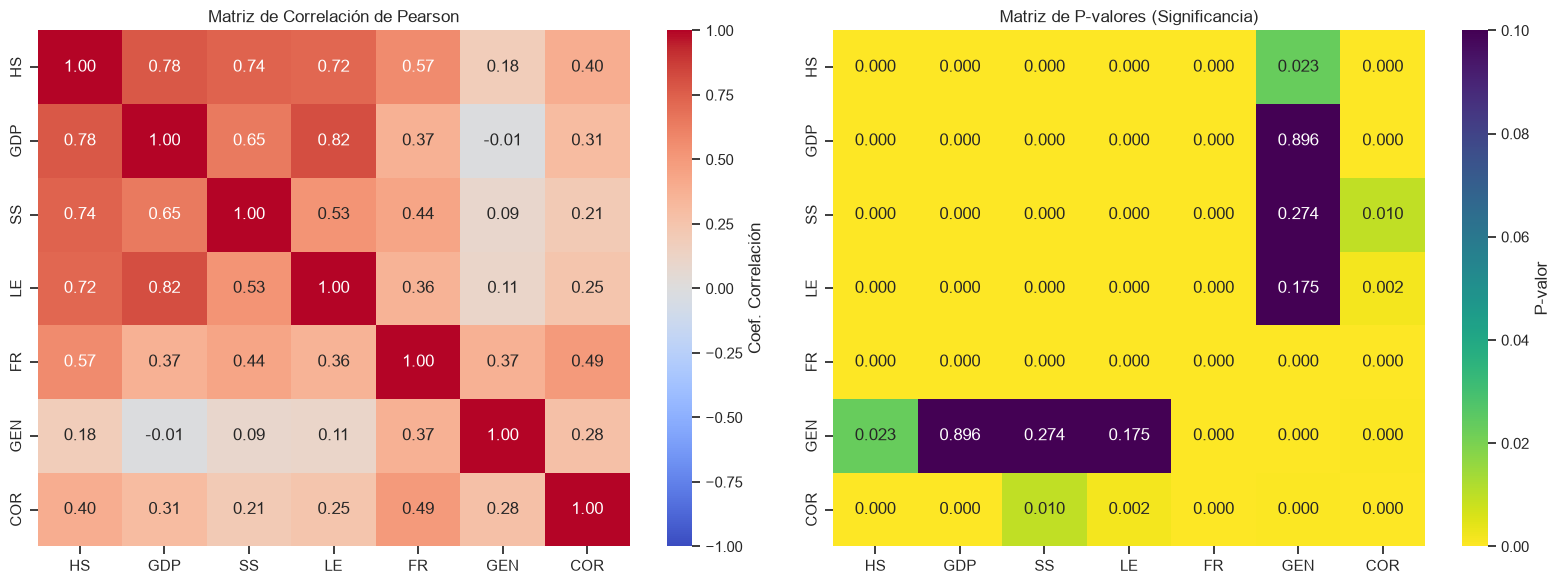

In [15]:
from scipy.stats import pearsonr

corr_matrix = df_subset.corr(method='pearson')

n_vars = len(variables)
pval_matrix = pd.DataFrame(np.zeros((n_vars, n_vars)), columns=variables, index=variables)

for i, col1 in enumerate(variables):
    for col2 in variables[i+1:]:
        p = float(pearsonr(df_subset[col1], df_subset[col2]).pvalue)
        pval_matrix.loc[col1, col2] = p
        pval_matrix.loc[col2, col1] = p

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1,
            ax=axes[0], cbar_kws={'label': 'Coef. Correlación'})
axes[0].set_title('Matriz de Correlación de Pearson')

sns.heatmap(pval_matrix, annot=True, fmt=".3f", cmap='viridis_r', vmin=0, vmax=0.1,
            ax=axes[1], cbar_kws={'label': 'P-valor'})
axes[1].set_title('Matriz de P-valores (Significancia)')

plt.tight_layout()
plt.show()

In [16]:
pares = []
for i, c1 in enumerate(variables):
    for c2 in variables[i+1:]:
        pares.append({'Variables': f'{c1} – {c2}',
                      'r': round(corr_matrix.loc[c1, c2], 2),
                      'P-valor': pval_matrix.loc[c1, c2]})
tabla = pd.DataFrame(pares)
tabla['Significativa (α=0.05)'] = tabla['P-valor'] < 0.05
tabla['P-valor'] = tabla['P-valor'].apply(lambda p: '< 0.001' if p < 0.001 else f'{p:.3f}')
print(tabla.to_string(index=False))

Variables     r P-valor  Significativa (α=0.05)
 HS – GDP  0.78 < 0.001                    True
  HS – SS  0.74 < 0.001                    True
  HS – LE  0.72 < 0.001                    True
  HS – FR  0.57 < 0.001                    True
 HS – GEN  0.18   0.023                    True
 HS – COR  0.40 < 0.001                    True
 GDP – SS  0.65 < 0.001                    True
 GDP – LE  0.82 < 0.001                    True
 GDP – FR  0.37 < 0.001                    True
GDP – GEN -0.01   0.896                   False
GDP – COR  0.31 < 0.001                    True
  SS – LE  0.53 < 0.001                    True
  SS – FR  0.44 < 0.001                    True
 SS – GEN  0.09   0.274                   False
 SS – COR  0.21   0.010                    True
  LE – FR  0.36 < 0.001                    True
 LE – GEN  0.11   0.175                   False
 LE – COR  0.25   0.002                    True
 FR – GEN  0.37 < 0.001                    True
 FR – COR  0.49 < 0.001                 

¿Qué correlaciones son significativas?

Con un nivel de significancia α = 0.05 y las hipótesis H₀: ρ = 0 (no existe relación lineal) vs H₁: ρ ≠ 0 (existe relación lineal), las correlaciones significativas son:

| Variables | r de Pearson | P-valor | Interpretación |
|---|---:|---:|---|
| HS – GDP | 0.78 | < 0.001 | Se relacionan de forma positiva. Como p < 0.05, existe suficiente evidencia para rechazar H₀, por lo cual las variables HS y GDP tienen una relación lineal significativa. |
| HS – SS | 0.74 | < 0.001 | Se relacionan de forma positiva. Como p < 0.05, existe suficiente evidencia para rechazar H₀, por lo cual las variables HS y SS tienen una relación lineal significativa. |
| HS – LE | 0.72 | < 0.001 | Se relacionan de forma positiva. Como p < 0.05, existe suficiente evidencia para rechazar H₀, por lo cual las variables HS y LE tienen una relación lineal significativa. |
| HS – FR | 0.57 | < 0.001 | Se relacionan de forma positiva. Como p < 0.05, existe suficiente evidencia para rechazar H₀, por lo cual las variables HS y FR tienen una relación lineal significativa. |
| HS – GEN | 0.18 | 0.023 | Se relacionan de forma positiva débil. Como p < 0.05, existe suficiente evidencia para rechazar H₀, por lo cual las variables HS y GEN tienen una relación lineal significativa. |
| HS – COR | 0.40 | < 0.001 | Se relacionan de forma positiva. Como p < 0.05, existe suficiente evidencia para rechazar H₀, por lo cual las variables HS y COR tienen una relación lineal significativa. |
| GDP – SS | 0.65 | < 0.001 | Se relacionan de forma positiva. Como p < 0.05, existe suficiente evidencia para rechazar H₀, por lo cual las variables GDP y SS tienen una relación lineal significativa. |
| GDP – LE | 0.82 | < 0.001 | Se relacionan de forma positiva. Como p < 0.05, existe suficiente evidencia para rechazar H₀, por lo cual las variables GDP y LE tienen una relación lineal significativa. |
| GDP – FR | 0.37 | < 0.001 | Se relacionan de forma positiva. Como p < 0.05, existe suficiente evidencia para rechazar H₀, por lo cual las variables GDP y FR tienen una relación lineal significativa. |
| GDP – COR | 0.31 | < 0.001 | Se relacionan de forma positiva. Como p < 0.05, existe suficiente evidencia para rechazar H₀, por lo cual las variables GDP y COR tienen una relación lineal significativa. |
| SS – LE | 0.53 | < 0.001 | Se relacionan de forma positiva. Como p < 0.05, existe suficiente evidencia para rechazar H₀, por lo cual las variables SS y LE tienen una relación lineal significativa. |
| SS – FR | 0.44 | < 0.001 | Se relacionan de forma positiva. Como p < 0.05, existe suficiente evidencia para rechazar H₀, por lo cual las variables SS y FR tienen una relación lineal significativa. |
| SS – COR | 0.21 | 0.010 | Se relacionan de forma positiva débil. Como p < 0.05, existe suficiente evidencia para rechazar H₀, por lo cual las variables SS y COR tienen una relación lineal significativa. |
| LE – FR | 0.36 | < 0.001 | Se relacionan de forma positiva. Como p < 0.05, existe suficiente evidencia para rechazar H₀, por lo cual las variables LE y FR tienen una relación lineal significativa. |
| LE – COR | 0.25 | 0.002 | Se relacionan de forma positiva débil. Como p < 0.05, existe suficiente evidencia para rechazar H₀, por lo cual las variables LE y COR tienen una relación lineal significativa. |
| FR – GEN | 0.37 | < 0.001 | Se relacionan de forma positiva. Como p < 0.05, existe suficiente evidencia para rechazar H₀, por lo cual las variables FR y GEN tienen una relación lineal significativa. |
| FR – COR | 0.49 | < 0.001 | Se relacionan de forma positiva. Como p < 0.05, existe suficiente evidencia para rechazar H₀, por lo cual las variables FR y COR tienen una relación lineal significativa. |
| GEN – COR | 0.28 | < 0.001 | Se relacionan de forma positiva débil. Como p < 0.05, existe suficiente evidencia para rechazar H₀, por lo cual las variables GEN y COR tienen una relación lineal significativa. |


#### Calcule la determinante de la matriz de covarianza. Viendo este número, ¿consideras que hay multicolinealidad?

In [17]:
det_cov = np.linalg.det(df_subset.cov())
print(f"Determinante de la matriz de covarianza: {det_cov}")

det_corr = np.linalg.det(df_subset.corr())
print(f"Determinante de la matriz de correlación: {det_corr}")

Determinante de la matriz de covarianza: 9.795950063732148e-11
Determinante de la matriz de correlación: 0.01933439698425528


 ¿consideras que hay multicolinealidad?

 Sí se considera que existe multicolinealidad, ya que el determinante de la matriz de correlación (0.0193) es cercano a cero, lo cual indica cierta dependencia lineal entre las variables. Sin embargo, no es severa, ya que el valor no es extremadamente pequeño. El determinante de la matriz de covarianza (9.80 × 10⁻¹¹) no aporta información útil, ya que depende de las unidades y escalas de las variables; en cambio, el determinante de la matriz de correlación está acotado entre 0 y 1 y sí permite evaluar la multicolinealidad.

#### Muestre los histogramas de cada variable, los box-plots, y las gráficas de quantil-quantil para mostrar si tiene un comportamiento normal las variables.

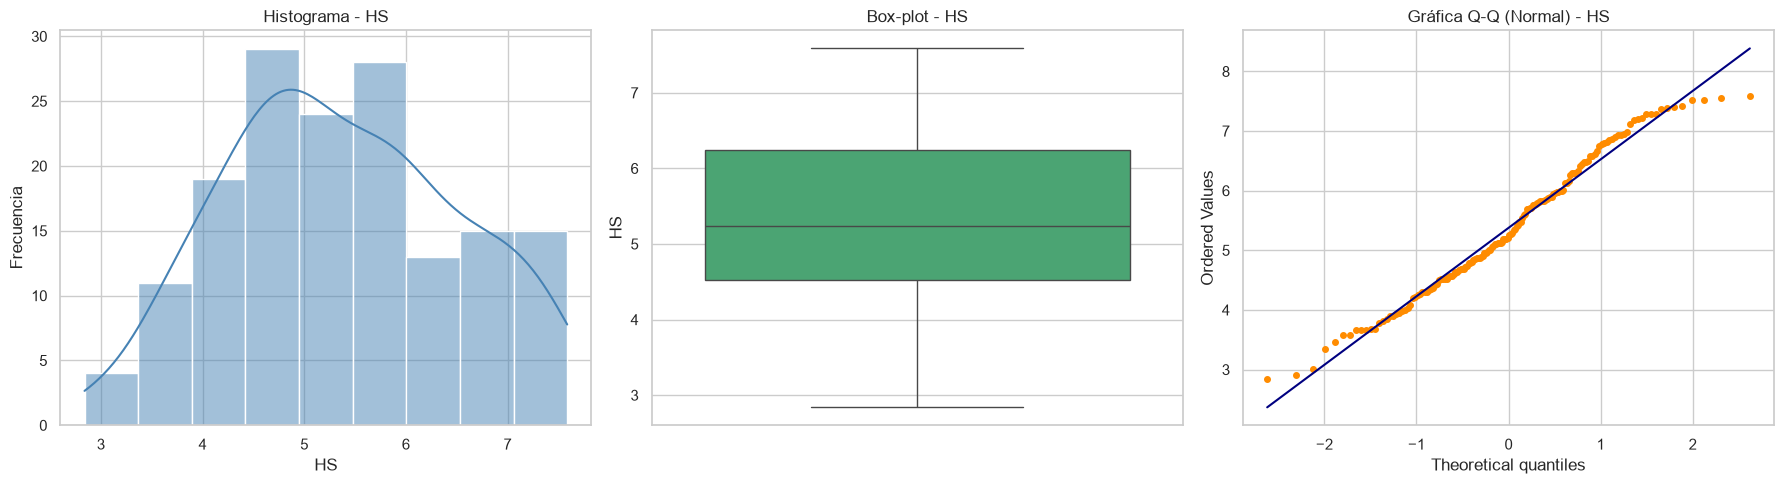

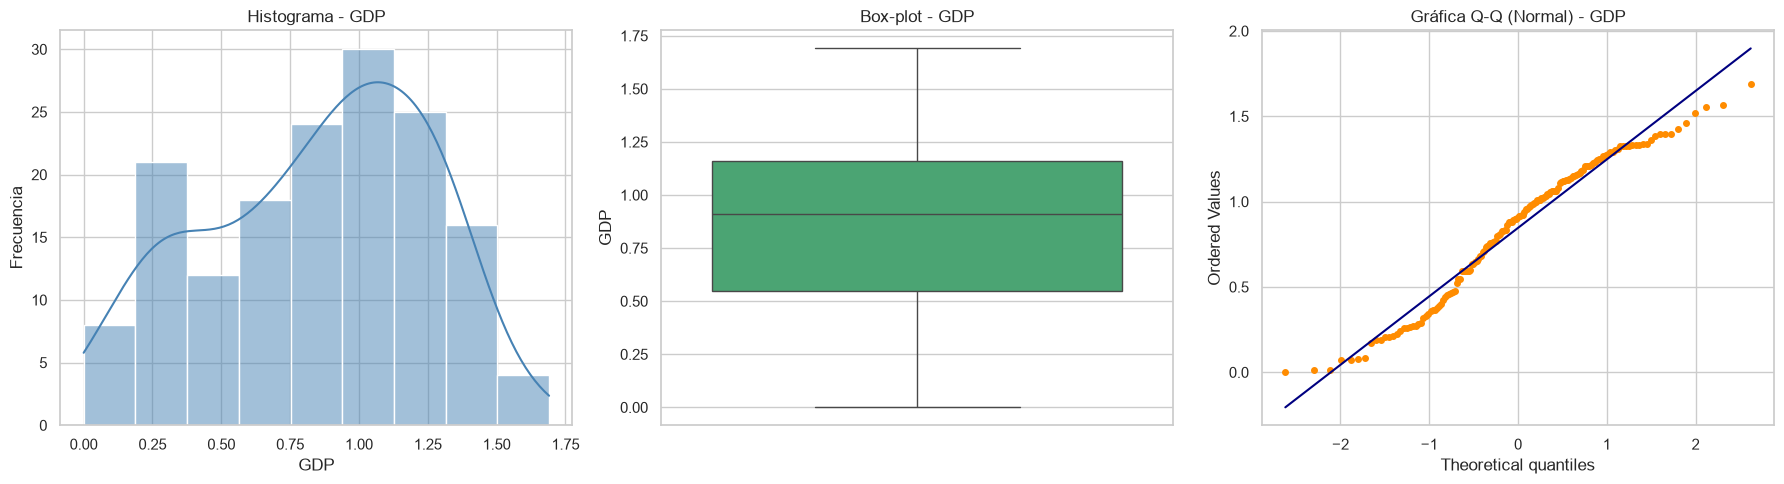

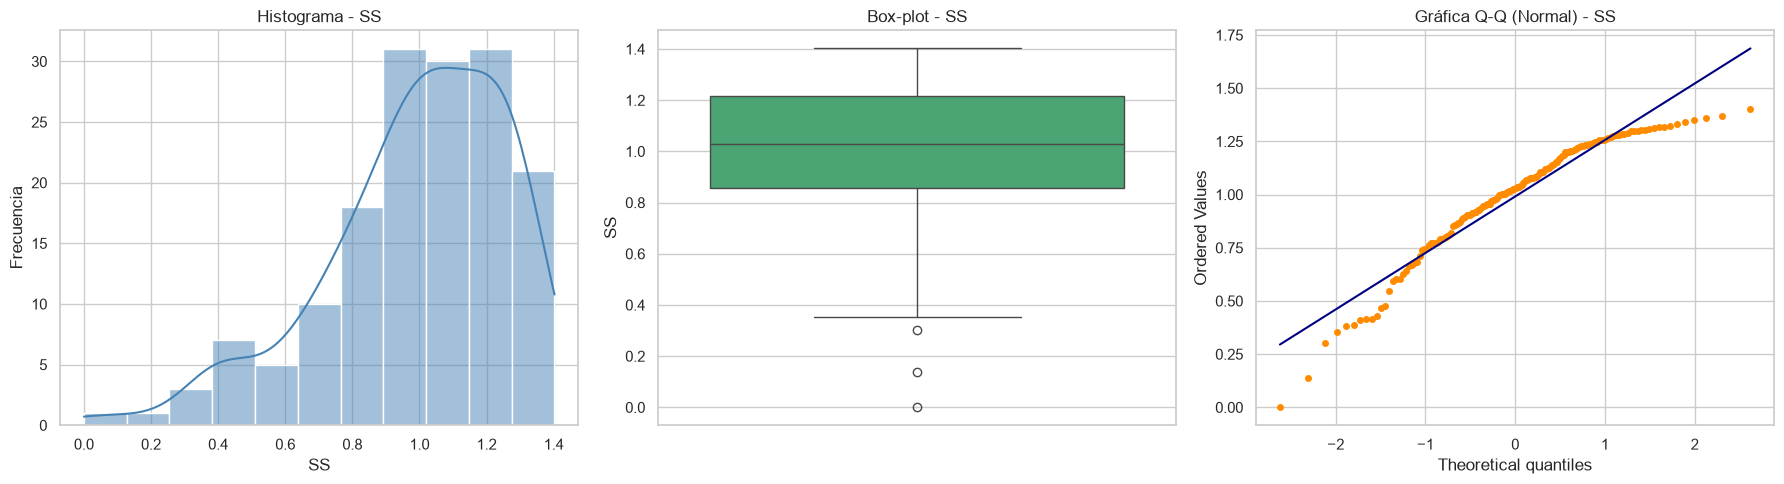

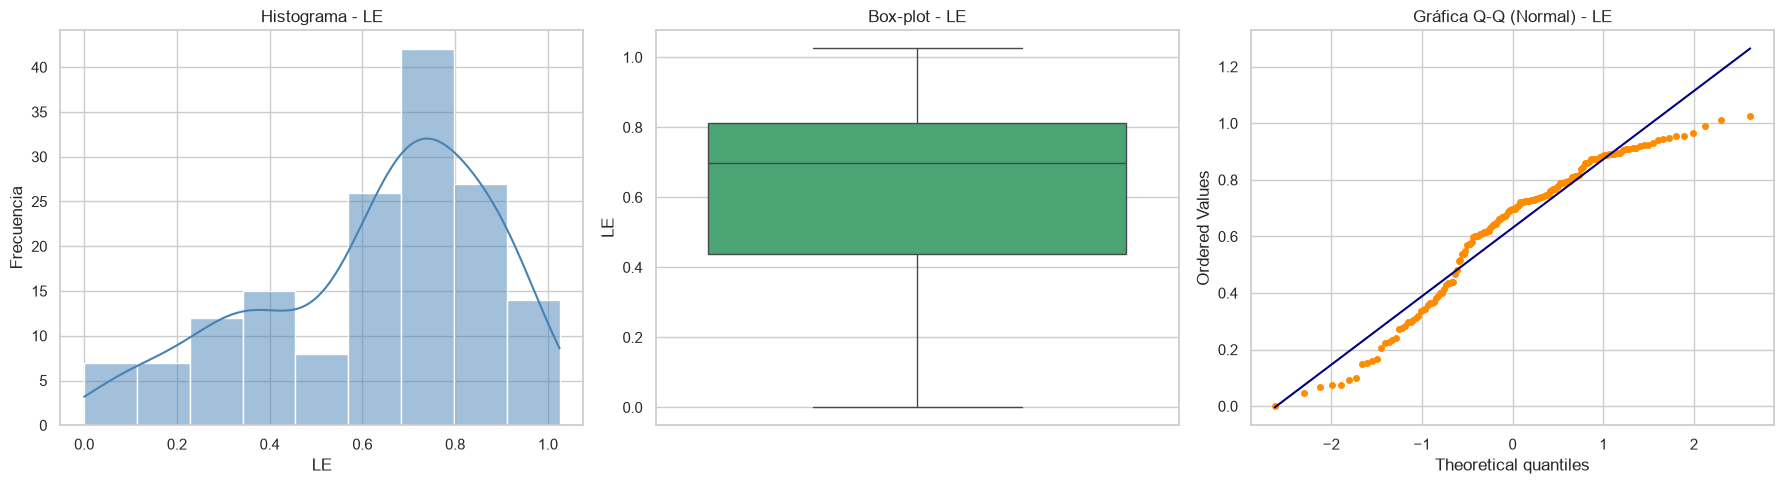

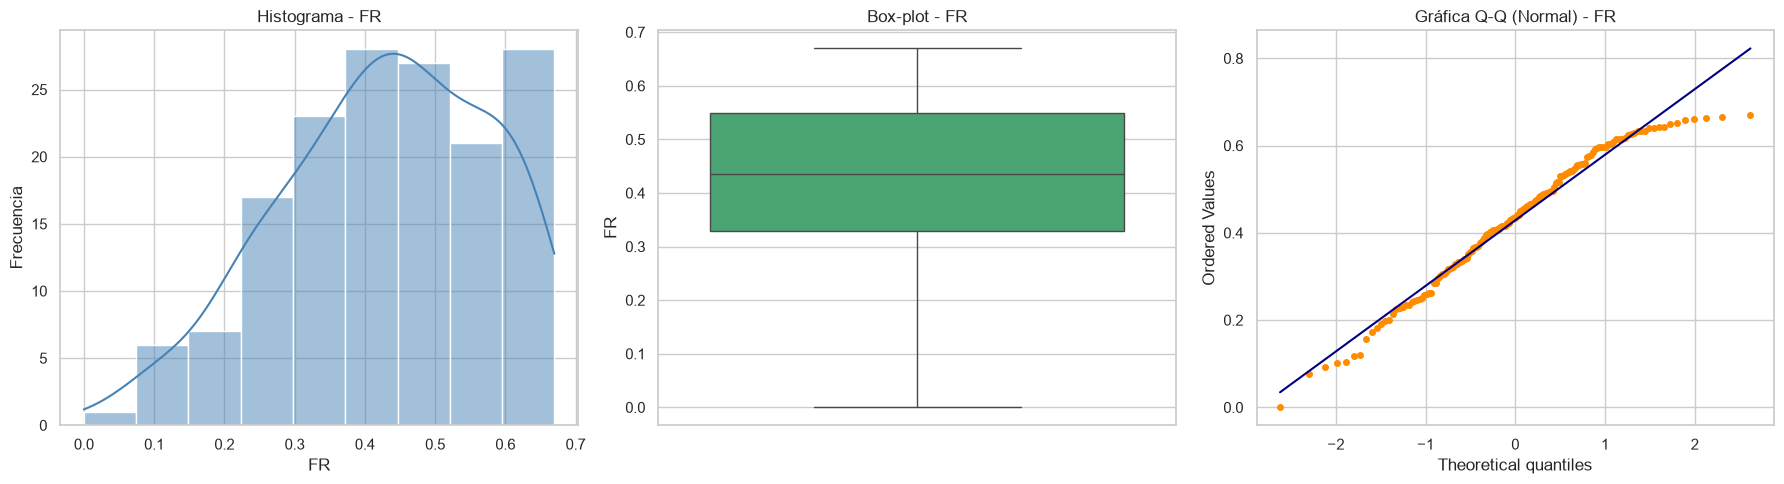

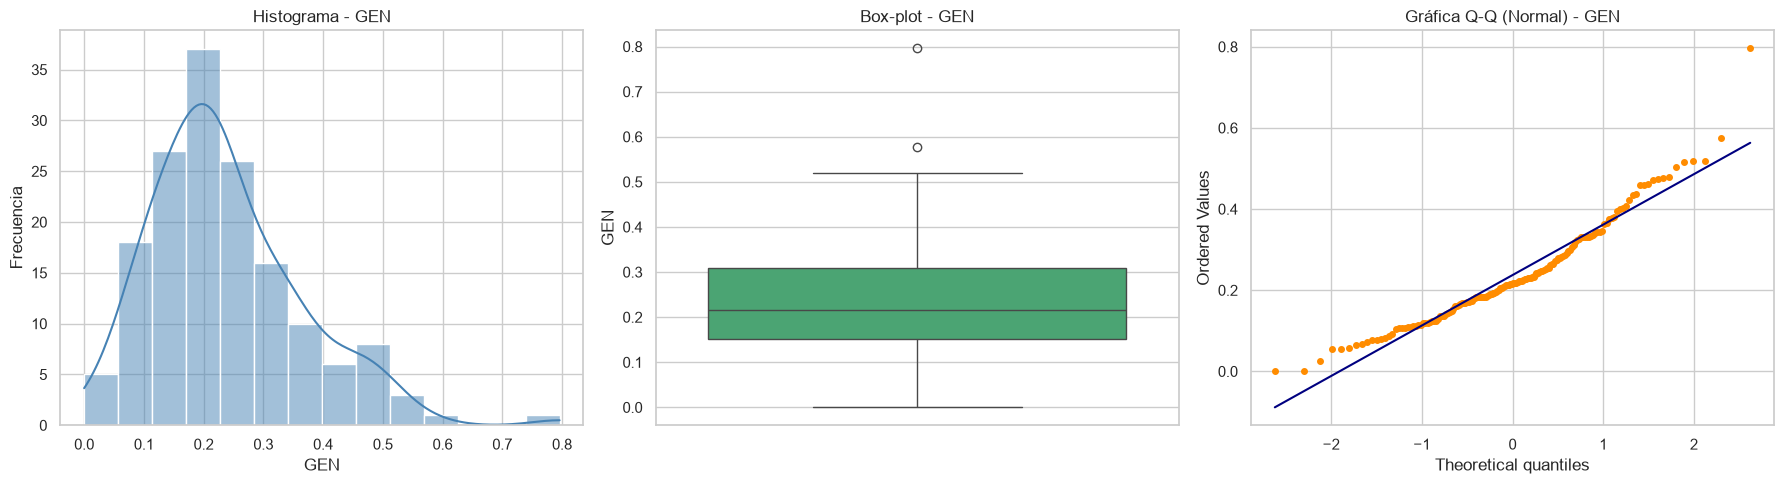

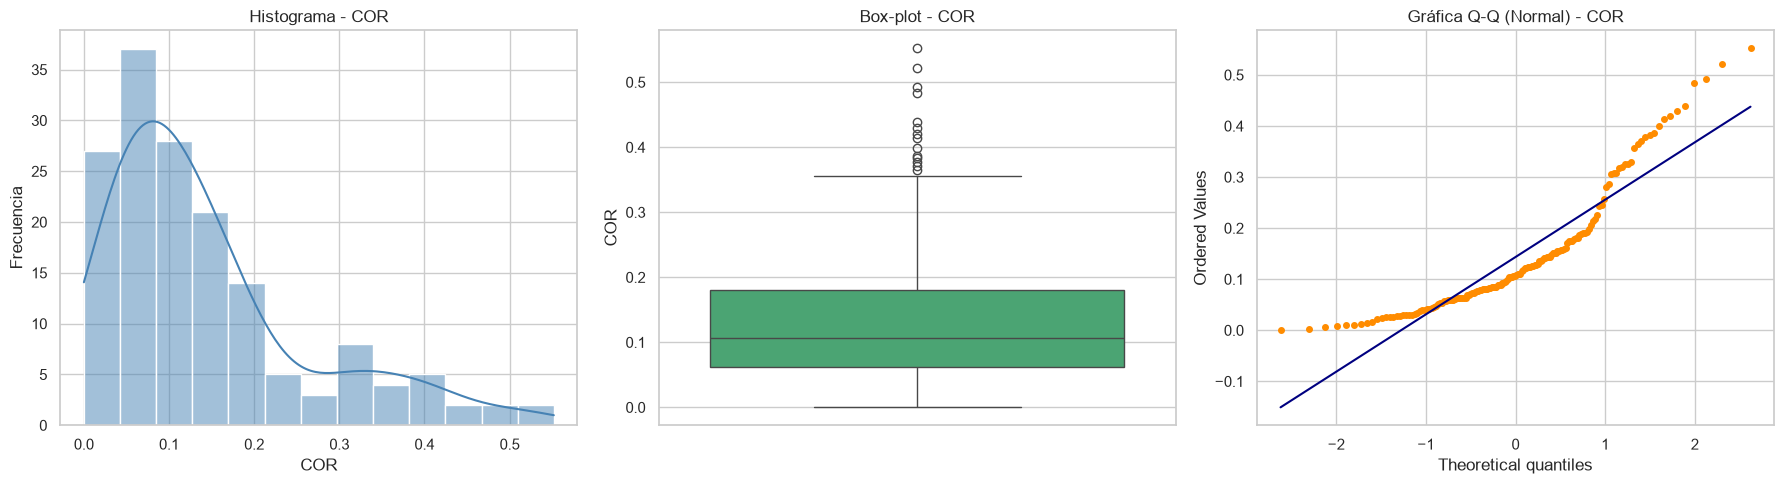

In [18]:
import scipy.stats as stats

sns.set_theme(style="whitegrid")

for var in variables:
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    sns.histplot(df[var], kde=True, ax=axes[0], color='steelblue')
    axes[0].set_title(f'Histograma - {var}')
    axes[0].set_xlabel(var)
    axes[0].set_ylabel('Frecuencia')

    sns.boxplot(y=df[var], ax=axes[1], color='mediumseagreen')
    axes[1].set_title(f'Box-plot - {var}')
    axes[1].set_ylabel(var)

    stats.probplot(df[var], dist="norm", plot=axes[2])
    axes[2].set_title(f'Gráfica Q-Q (Normal) - {var}')
    axes[2].get_lines()[0].set_marker('o')
    axes[2].get_lines()[0].set_markersize(4)
    axes[2].get_lines()[0].set_color('darkorange')
    axes[2].get_lines()[1].set_color('navy')

    plt.tight_layout()
    plt.show()

#### Detecte valores atípicos utilizando el método de la distancia de Mahalanobis. ¿Qué acciones tomarías para los valores atípicos encontrados?

In [19]:
from scipy.stats import chi2

mean_vector = df_subset.mean()
inv_cov_matrix = np.linalg.inv(df_subset.cov(ddof=1))

def mahalanobis(row):
    diff = row - mean_vector
    return np.sqrt(diff @ inv_cov_matrix @ diff)

df['Mahalanobis_Dist'] = df_subset.apply(mahalanobis, axis=1)
df['Mahalanobis_P_Value'] = chi2.sf(df['Mahalanobis_Dist']**2, df=len(variables))

cols = ['country'] + variables + ['Mahalanobis_Dist', 'Mahalanobis_P_Value']

for alpha in [0.01, 0.001]:
    outliers = df[df['Mahalanobis_P_Value'] < alpha]
    print(f"--- OBSERVACIONES ATÍPICAS con alpha = {alpha} ---")
    print(outliers[cols])

--- OBSERVACIONES ATÍPICAS con alpha = 0.01 ---
                      country     HS      GDP       SS       LE       FR  \
127                  Botswana  4.332  0.99355  1.10464  0.04776  0.49495   
128                   Myanmar  4.307  0.27108  0.70905  0.48246  0.44017   
147  Central African Republic  3.678  0.07850  0.00000  0.06699  0.48879   
153                    Rwanda  3.465  0.22208  0.77370  0.42864  0.59201   
155                     Syria  3.006  0.66320  0.47489  0.72193  0.15684   

         GEN      COR  Mahalanobis_Dist  Mahalanobis_P_Value  
127  0.10461  0.12474          4.978344             0.000829  
128  0.79588  0.19034          4.834511             0.001468  
147  0.23835  0.08289          4.922740             0.001037  
153  0.22628  0.55191          5.400414             0.000135  
155  0.47179  0.18906          4.685166             0.002591  
--- OBSERVACIONES ATÍPICAS con alpha = 0.001 ---
      country     HS      GDP       SS       LE       FR      GEN   

 ¿Qué acciones tomarías para los valores atípicos encontrados

 Con un nivel de significancia α = 0.01 se identificaron cinco países atípicos (Botswana, Myanmar, República Centroafricana, Rwanda y Siria), y con α = 0.001 solo Botswana y Rwanda. Estos países presentan combinaciones inusuales de valores; por ejemplo, Botswana tiene un GDP y un apoyo social altos pero una esperanza de vida muy baja, lo que causa estos datos atipicos. Como en este caso se tratan de valores reales, se decide conservar las observaciones. En caso de afectar en gran medida al análisis se podrian eliminar estos registros.

#### Aplique análisis de componentes principales sobre tu conjunto de datos, e indique con cuantos componentes se puede representar los datos para una variabilidad por encima del 90%. 

In [20]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

X_scaled = StandardScaler().fit_transform(df_subset)

pca = PCA()
X_pca = pca.fit_transform(X_scaled)

varianza_explicada = pca.explained_variance_ratio_
varianza_acumulada = np.cumsum(varianza_explicada)
n_componentes_90 = np.argmax(varianza_acumulada >= 0.90) + 1

print("--- RESULTADOS PCA ---")
for i, (v, a) in enumerate(zip(varianza_explicada, varianza_acumulada), 1):
    print(f"Componente {i}: {v*100:.2f}% de varianza (Acumulada: {a*100:.2f}%)")
print(f"\nNúmero de componentes necesarios para > 90% de varianza: {n_componentes_90}")

--- RESULTADOS PCA ---
Componente 1: 52.67% de varianza (Acumulada: 52.67%)
Componente 2: 19.11% de varianza (Acumulada: 71.78%)
Componente 3: 10.07% de varianza (Acumulada: 81.85%)
Componente 4: 8.05% de varianza (Acumulada: 89.90%)
Componente 5: 5.53% de varianza (Acumulada: 95.42%)
Componente 6: 2.45% de varianza (Acumulada: 97.87%)
Componente 7: 2.13% de varianza (Acumulada: 100.00%)

Número de componentes necesarios para > 90% de varianza: 5


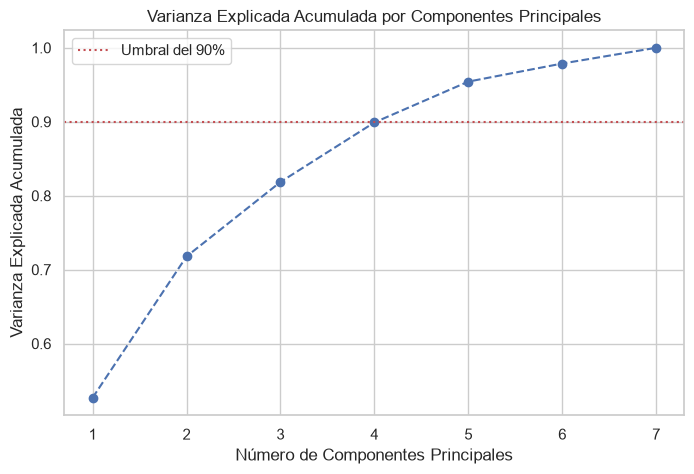

In [21]:
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(varianza_acumulada) + 1), varianza_acumulada,
         marker='o', linestyle='--', color='b')
plt.axhline(y=0.90, color='r', linestyle=':', label='Umbral del 90%')
plt.title('Varianza Explicada Acumulada por Componentes Principales')
plt.xlabel('Número de Componentes Principales')
plt.ylabel('Varianza Explicada Acumulada')
plt.grid(True)
plt.legend()
plt.show()

A través del PCA se puede concluir que el primer componente explica el 52.67 % de la varianza y el segundo el 19.11 %, acumulando un 71.78 % con dos componentes. Usando un umbral del 90 % de varianza explicada se requieren 5 componentes principales (95.42 %), ya que con 4 componentes se alcanza el 89.90 %, valor ligeramente inferior al umbral. Por lo tanto, es posible reducir la dimensionalidad del problema de 7 variables a 5 componentes principales sin perder una gran cantidad de información.

#### Considera a happiness_score (HS) como un grupo de variables, y al resto como otro grupo de variables, y realiza el análisis de correlación canónica sobre los grupos de variables

In [22]:
import statsmodels.api as sm
from sklearn.cross_decomposition import CCA
from scipy.stats import f as f_dist

y1 = df[['HS']]                                     # Grupo 1: happiness_score
y2 = df[['GDP', 'SS', 'LE', 'FR', 'GEN', 'COR']]    # Grupo 2: el resto

# 1. Correlación canónica con sklearn (1 componente, porque el grupo 1 tiene 1 variable)
cca = CCA(n_components=1, scale=True)
u, v = cca.fit_transform(y1, y2)
r_canonica = np.corrcoef(u[:, 0], v[:, 0])[0, 1]

print("--- CORRELACIÓN CANÓNICA ---")
print(f"r = {abs(r_canonica):.4f}   r² = {r_canonica**2:.4f}")

# 2. Pesos canónicos (sobre variables estandarizadas, comparables entre sí)
print("\nPesos canónicos Grupo 1 (HS):", cca.x_weights_.ravel())
print("\nPesos canónicos Grupo 2:")
print(pd.Series(cca.y_weights_.ravel(), index=y2.columns))

# 3. Prueba de significancia (equivale a la prueba F de la regresión múltiple)
n, p = y2.shape
r2 = r_canonica**2
wilks = 1 - r2
F = (r2 / p) / ((1 - r2) / (n - p - 1))
p_valor = f_dist.sf(F, p, n - p - 1)

print("\n--- PRUEBA DE SIGNIFICANCIA ---")
print(f"Wilks' lambda = {wilks:.4f}")
print(f"F({p}, {n-p-1}) = {F:.4f}")
print(f"P-valor = {p_valor:.4g}")

--- CORRELACIÓN CANÓNICA ---
r = 0.8816   r² = 0.7772

Pesos canónicos Grupo 1 (HS): [1.]

Pesos canónicos Grupo 2:
GDP    0.564782
SS     0.624671
LE     0.392276
FR     0.327099
GEN    0.080208
COR    0.153297
dtype: float64

--- PRUEBA DE SIGNIFICANCIA ---
Wilks' lambda = 0.2228
F(6, 151) = 87.8092
P-valor = 1.043e-46


Como solo hay una variable en el grupo 1 (HS), existe un único par canónico y la correlación canónica equivale a la correlación múltiple entre HS y las otras seis variables. Se obtuvo una correlación canónica de r = 0.8816 (r² = 0.7772), por lo que las variables del grupo 2 explican cerca del 78 % de la variabilidad de happiness_score. La relación es significativa (Wilks' lambda = 0.2228, F(6, 151) = 87.81, p < 0.001), por lo que existe suficiente evidencia para rechazar H₀ y concluir que hay relación lineal entre ambos grupos. 

#### Conclusion de resultados

En el ejercicio se encontró que happiness_score (HS) se relaciona principalmente de forma positiva con GDP, SS y LE,  mientras que la generosidad (GEN) casi no tiene ningun efecto. También se concluyó que existe multicolinealidad, al tener un determinante de la matriz de correlación de 0.0193, cercano a cero, y mediante PCA se obtuvo que se necesitan 5 componentes para superar el 90 % de la varianza. Mediante la distancia de Mahalanobis se identificaron países atípicos (como Botswana y Rwanda), los cuales se conservaron por tratarse de valores reales. Al final, mediante la correlación canónica se obtuvo que las variables del grupo 2 están ligadas fuertemente y de forma significativa con HS (r = 0.88, p < 0.001), explicando cerca del 78 % de su variabilidad.

#### Investigue sobre CCA, y conteste la siguiente pregunta: si en correlación canónica uno de los grupos de variables tiene una sola variable, ¿qué ocurre? ¿Aporta información nueva? ¿Cómo se relaciona esto con la regresión lineal?

En este caso la correlación canónica se convierte en un caso particular de la regresión lineal múltiple, ya que solo existe un par canónico (el número de pares es el mínimo entre los tamaños de los dos grupos). La CCA es equivalente a la regresión lineal múltiple y no aporta información nueva. Lo único diferente sería el enfoque: mientras que la regresión lineal múltiple busca explicar o predecir la variable dependiente, la CCA busca maximizar la correlación entre los dos grupos, pero con una sola variable en un grupo ambos enfoques llegan al mismo resultado.

La relación con la regresión es directa: la correlación canónica es igual a la correlación múltiple R de la regresión, su cuadrado es el coeficiente de determinación R², los pesos canónicos son proporcionales a los coeficientes de regresión y la prueba de significancia equivale a la prueba F global. Por lo tanto, la CCA puede entenderse como una generalización de la regresión lineal, útil cuando ambos grupos tienen varias variables.

# Ejercicio 3
![](foto.png)

En esta tabla, A representa los dos últimos dígitos de la matrícula de uno de los integrantes del equipo, B es el antepenúltimo dígito de la matrícula de uno de los integrantes del equipo, y C es el día de la semana favorito (del 1 al 7, comenzando por el domingo) de otro de los integrantes del equipo.

* Desarrolle tres iteraciones del método de imputación múltiple por ecuaciones encadenadas (MICE) para encontrar los datos faltantes. Los modelos de regresión de cada paso los puedes obtener con Python con cualquier librería.
* Pruebe el algoritmo de imputación múltiple disponible en la librería Scikit-learn con esta tabla, y compare los resultados obtenidos con los que tuviste en tu desarrollo.


#### Comparación

In [23]:
import warnings
import numpy as np

from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.linear_model import LinearRegression
from sklearn.exceptions import ConvergenceWarning

np.set_printoptions(precision=4, suppress=True)

X = np.array([
    [4,      3,      np.nan],
    [2,      5,      45],
    [1,      2.5,    15],
    [np.nan, 5,      70],
    [4,      np.nan, 92],
    [7,      12,     np.nan]
], dtype=float)

# Desarrollo de las tres iteraciones.
faltantes = np.isnan(X)
Y = np.where(faltantes, np.nanmean(X, axis=0), X)

for iteracion in range(1, 4):
    for j in range(3):
        observados = ~faltantes[:, j]
        predictores = np.arange(3) != j

        modelo = LinearRegression()
        modelo.fit(
            Y[observados][:, predictores],
            X[observados, j]
        )

        Y[faltantes[:, j], j] = modelo.predict(
            Y[faltantes[:, j]][:, predictores]
        )

        print(
            f"Iteración {iteracion}, variable x{j+1}:",
            "intercepto =", modelo.intercept_,
            "coeficientes =", modelo.coef_
        )

    print("Tabla al finalizar la iteración:")
    print(Y)

# tol=0 fuerza las tres rondas completas
with warnings.catch_warnings():
    warnings.simplefilter("ignore", ConvergenceWarning)

    imputador_lineal = IterativeImputer(
        estimator=LinearRegression(),
        max_iter=3,
        tol=0,
        initial_strategy="mean",
        imputation_order="roman",
        sample_posterior=False,
        random_state=0
    )
    resultado_lineal = imputador_lineal.fit_transform(X)


print("\nScikit-learn con regresión lineal:")
print(resultado_lineal)


Iteración 1, variable x1: intercepto = -0.31288512931163437 coeficientes = [0.4577 0.0257]
Iteración 1, variable x2: intercepto = 2.0015198926119537 coeficientes = [ 1.7251 -0.0546]
Iteración 1, variable x3: intercepto = -3.2061005621400653 coeficientes = [22.6239 -0.542 ]
Tabla al finalizar la iteración:
[[  4.       3.      85.6634]
 [  2.       5.      45.    ]
 [  1.       2.5     15.    ]
 [  3.7718   5.      70.    ]
 [  4.       3.8759  92.    ]
 [  7.      12.     148.6568]]
Iteración 2, variable x1: intercepto = 0.08342828716144046 coeficientes = [0.0418 0.0427]
Iteración 2, variable x2: intercepto = 0.49593119850877354 coeficientes = [ 2.2902 -0.0399]
Iteración 2, variable x3: intercepto = -16.26928521443969 coeficientes = [20.7596  3.9875]
Tabla al finalizar la iteración:
[[  4.       3.      78.7315]
 [  2.       5.      45.    ]
 [  1.       2.5     15.    ]
 [  3.2786   5.      70.    ]
 [  4.       5.9822  92.    ]
 [  7.      12.     176.8975]]
Iteración 3, variable x1: